In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import precision_recall_curve, roc_curve, auc
import ast, os, sys

sys.path.insert(0, os.path.join(os.getcwd(), "..", "scripts"))
from utility_functions import read_fasta, read_parrot_preds

In [2]:
# Parameters to make figures work better with illustrator 
import matplotlib 
# For higher resoltion figures
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plt.rcParams["font.family"] = "Helvetica"
plt.rcParams['pdf.fonttype'] = 42

In [3]:
# Predictions for things in the test set - all consensus model 
predictions_all_six = pd.read_table('consensus_model_all_six_predictions.tsv', header=None, sep=' ', names=list(range(1444)))
# predictions_all_six = pd.read_table('test_preds_parrot_all_six_model.csv', header=None, sep=' ', names=list(range(1444)))

predictions_all_six['label'] = [s.split('_')[-1] for s in predictions_all_six[0]]
predictions_all_six

,0,1,2,3,4,5,6,7,8,9,...,1435,1436,1437,1438,1439,1440,1441,1442,1443,label
0,Aco021664.1_TRUE,MELERQDKEEEEEEEEELLRTAAAVPMHRFIVPKPEPMELFGSLQL...,0.000000,0.000000,0.000000,0.166667,0.166667,0.166667,0.166667,0.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
1,Aco021664.1_PRED,MELERQDKEEEEEEEEELLRTAAAVPMHRFIVPKPEPMELFGSLQL...,-0.023056,-0.017209,-0.020633,-0.009910,0.001139,-0.015355,-0.029935,-0.003406,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
2,Aco004479.1_TRUE,MDPDAEVIALSPKTLLATNRFLCEICGKGFQRDQNLQLHRRGHNLP...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
3,Aco004479.1_PRED,MDPDAEVIALSPKTLLATNRFLCEICGKGFQRDQNLQLHRRGHNLP...,0.009925,0.000895,0.005281,0.005157,0.006867,0.006989,0.006614,0.013375,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
4,Aqcoe2G434100.1.p_TRUE,MDTADITYSSTNFSPKDQVVGIDDQEMREGHLHVLNDIDLEKSDET...,0.166667,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333,0.333333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69079,g003332.m1_yHMPu5000035652_torulaspora_maleeae...,MESVPNLDLLDSFGLENDKEIDFETAYRMFSNFDDDIARPQDDSMF...,0.667342,0.690514,0.706405,0.725633,0.726018,0.768686,0.748264,0.747952,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
69080,g002783.m1_yHMPu5000035653_torulaspora_delbrue...,MDSGPENDVFDLFGLENDKDIDFETAYKMISKFDEEISLFNDGSAL...,0.666667,0.833333,0.833333,0.833333,0.833333,0.833333,0.833333,0.833333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
69081,g002783.m1_yHMPu5000035653_torulaspora_delbrue...,MDSGPENDVFDLFGLENDKDIDFETAYKMISKFDEEISLFNDGSAL...,0.635907,0.650952,0.680603,0.710323,0.724234,0.737922,0.739415,0.726760,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
69082,g001796.m1_yHMPu5000035655_tetrapisispora_taiw...,MILSNNFFNLIADVESNDNEFDLSIDFDTAYNIFTKEFSIEQSIEN...,0.500000,0.500000,0.666667,0.666667,0.666667,0.666667,0.666667,0.666667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE


In [4]:
# Predictions for things in the test set - all consensus model 
predictions_all_six_regression = pd.read_table('consensus_model_all_six_regression_predictions.tsv', header=None, sep=' ', names=list(range(1444)))

predictions_all_six_regression['label'] = [s.split('_')[-1] for s in predictions_all_six_regression[0]]
predictions_all_six_regression

,0,1,2,3,4,5,6,7,8,9,...,1435,1436,1437,1438,1439,1440,1441,1442,1443,label
0,Aco030142.1_TRUE,MVRGRREMRRIENATSRQVTFSKRRNGLLKKAFELSVLCDAEVALV...,0.104426,0.104423,0.104420,0.104419,0.104421,0.104420,0.104428,0.104431,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
1,Aco030142.1_PRED,MVRGRREMRRIENATSRQVTFSKRRNGLLKKAFELSVLCDAEVALV...,0.117196,0.120204,0.112070,0.105779,0.111313,0.106649,0.097530,0.093411,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
2,Aqcoe2G305100.1.p_TRUE,MVDNIGGWSSTTGGHKVKVGGGGATSSTSADEKGCFKEQDRLLPIA...,0.095308,0.095135,0.095165,0.095044,0.095156,0.095122,0.095163,0.095132,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
3,Aqcoe2G305100.1.p_PRED,MVDNIGGWSSTTGGHKVKVGGGGATSSTSADEKGCFKEQDRLLPIA...,0.125612,0.121198,0.111898,0.115752,0.116618,0.104724,0.099677,0.106739,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
4,Aqcoe5G030800.1.p_TRUE,MAGFGSPCGACKFLRRKCVRGCVFAPYFCHEQGATHFAAIHKVFGA...,0.116268,0.115949,0.115784,0.115844,0.115931,0.115816,0.115828,0.115870,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69033,g003553.m1_yHMPu5000035626_zygosaccharomyces_s...,MDSVGDGGNDMLDLFDLDNDNDIDFETAYKMISNFDDVASDGGQDE...,0.597280,0.598499,0.634678,0.665337,0.679940,0.698986,0.712692,0.763557,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
69034,g002783.m1_yHMPu5000035653_torulaspora_delbrue...,MDSGPENDVFDLFGLENDKDIDFETAYKMISKFDEEISLFNDGSAL...,0.520009,0.689495,0.697443,0.702040,0.687469,0.692967,0.702857,0.705612,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
69035,g002783.m1_yHMPu5000035653_torulaspora_delbrue...,MDSGPENDVFDLFGLENDKDIDFETAYKMISKFDEEISLFNDGSAL...,0.660000,0.648330,0.639379,0.659681,0.691821,0.702747,0.700624,0.665651,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PRED
69036,g004215.m1_yHMPu5000035666_nakaseomyces_bacill...,MDNDMFDMFDIDNDIDFETAYQIFSNQFEDKNSPQLLFDGEIELTG...,0.946407,1.126526,1.140928,1.141165,1.141518,1.141503,1.141867,1.141932,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE


In [5]:
# Extracting the parrot test output into true and predicted values 
# DF has _TRUE or _PRED suffixes
all_six_true_df = predictions_all_six[predictions_all_six['label'] == 'TRUE']
all_six_true_vals_ls = all_six_true_df.iloc[:, 2:1443].apply(lambda row: list(row.dropna()), axis=1).tolist()
all_six_true_vals_ls = [a for ls in all_six_true_vals_ls for a in ls]

all_six_pred_df = predictions_all_six[predictions_all_six['label'] == 'PRED']
all_six_pred_vals_ls = all_six_pred_df.iloc[:, 2:1443].apply(lambda row: list(row.dropna()), axis=1).tolist()
all_six_pred_vals_ls = [a for ls in all_six_pred_vals_ls for a in ls]

In [6]:
# Extracting the parrot test output into true and predicted values 
# DF has _TRUE or _PRED suffixes
all_six_regression_true_df = predictions_all_six_regression[predictions_all_six_regression['label'] == 'TRUE']
all_six_regression_true_vals_ls = all_six_regression_true_df.iloc[:, 2:1443].apply(lambda row: list(row.dropna()), axis=1).tolist()
all_six_regression_true_vals_ls = [a for ls in all_six_regression_true_vals_ls for a in ls]

all_six_regression_pred_df = predictions_all_six_regression[predictions_all_six_regression['label'] == 'PRED']
all_six_regression_pred_vals_ls = all_six_regression_pred_df.iloc[:, 2:1443].apply(lambda row: list(row.dropna()), axis=1).tolist()
all_six_regression_pred_vals_ls = [a for ls in all_six_regression_pred_vals_ls for a in ls]

In [7]:
all_six_true_df.iloc[995, 0]

'Pavir.8KG243100.1.p_TRUE'

In [8]:
all_six_regression_true_df.merge(all_six_true_df, on=0)

,0,1_x,2_x,3_x,4_x,5_x,6_x,7_x,8_x,9_x,...,1435_y,1436_y,1437_y,1438_y,1439_y,1440_y,1441_y,1442_y,1443_y,label_y
0,EMT22736_TRUE,MAEAEGQLAACWGKQDDEWRKGPWTTQEDKLLLDHVAQHGEGRWNS...,0.206371,0.206471,0.206569,0.206546,0.207376,0.206913,0.206585,0.206468,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
1,evm_27.model.AmTr_v1.0_scaffold00002.8_TRUE,MIPFVPPGFTLRDGYCYMNNTTTTTTTTTQCWDQGRYLQKLACKSS...,0.143316,0.144283,0.146076,0.152597,0.153303,0.157335,0.149142,0.152205,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
2,GSBRNA2T00064763001_TRUE,MMSQQEYPYDFSLMKTSSIYEVLDYSIAEQHSHPTENLSSLQAQGG...,0.280527,0.280223,0.279823,0.280436,0.283911,0.289629,0.290796,0.298088,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
3,Bathy02g00780_TRUE,MGDLKAVFSSLLGKESAKKVRKDKDKDKKKDKRKREKKEKKKKKKE...,0.092088,0.091619,0.091851,0.090962,0.090658,0.090683,0.090571,0.090485,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
4,Bv4_079320_gsmr.t2_TRUE,MFKGKVEVNQDGVSNSIDPSSRPNTDCVELVWENGQLMMQGKTRKS...,0.183837,0.183821,0.183872,0.183918,0.183891,0.183897,0.183889,0.183864,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5132,g003909.m1_yHMPu5000040918_candida_insectamans...,MNSSRILSPNQQLVYSSSQPHPPQPQLTAPSQNQLLGQPLHYYQPG...,0.117418,0.117396,0.117425,0.117498,0.117474,0.117423,0.117386,0.117360,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
5133,g003564.m1_yHMPu5000040933_candida_diddensiae_...,MFSKPVYNNIKYPQPQYQKSITRLPSFTEVLNQIQLPNEFPLNKPN...,0.137567,0.137549,0.137633,0.137583,0.137483,0.137483,0.137550,0.137508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
5134,g002834.m1_yHMPu5000041793_schwanniomyces_etch...,MLLGQASSVVQLKPSPVTLPSFSELVTSIPLPHEFKEQACAQSLNP...,0.158435,0.158371,0.158498,0.158412,0.158550,0.158528,0.158551,0.158998,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE
5135,g003553.m1_yHMPu5000035626_zygosaccharomyces_s...,MDSVGDGGNDMLDLFDLDNDNDIDFETAYKMISNFDDVASDGGQDE...,0.647849,0.825148,0.848870,0.875453,0.889509,0.914047,0.907421,0.930491,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE


In [9]:
all_six_regression_true_df.reset_index()[all_six_regression_true_df.reset_index()[0] == 'GSBRNA2T00064763001_TRUE']

,index,0,1,2,3,4,5,6,7,8,...,1435,1436,1437,1438,1439,1440,1441,1442,1443,label
36,72,GSBRNA2T00064763001_TRUE,MMSQQEYPYDFSLMKTSSIYEVLDYSIAEQHSHPTENLSSLQAQGG...,0.280527,0.280223,0.279823,0.280436,0.283911,0.289629,0.290796,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE


In [10]:
all_six_true_df.reset_index()[all_six_true_df.reset_index()[0] == 'GSBRNA2T00064763001_TRUE']

,index,0,1,2,3,4,5,6,7,8,...,1435,1436,1437,1438,1439,1440,1441,1442,1443,label
51,102,GSBRNA2T00064763001_TRUE,MMSQQEYPYDFSLMKTSSIYEVLDYSIAEQHSHPTENLSSLQAQGG...,0.166667,0.166667,0.166667,0.166667,0.166667,0.166667,0.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TRUE


Text(0, 0.5, 'Fraction of predictors\npredicting AD')

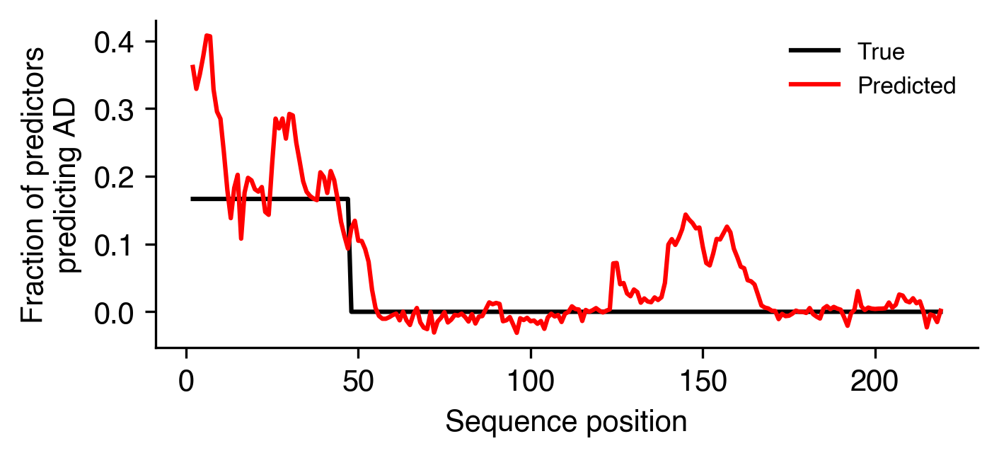

In [11]:
plt.subplots(1, 1, figsize=(5, 2))
# i=995
i=51
plt.plot(all_six_true_df.iloc[i, 2:1443].dropna(), color='black', label='True')
plt.plot(all_six_pred_df.iloc[i, 2:1443].dropna(), color='red', label='Predicted')
plt.legend(frameon=False, fontsize=8)

sns.despine()
plt.xlabel("Sequence position", fontsize=10)
plt.ylabel("Fraction of predictors\npredicting AD", fontsize=10)

Text(0, 0.5, 'Fraction of predictors\npredicting AD')

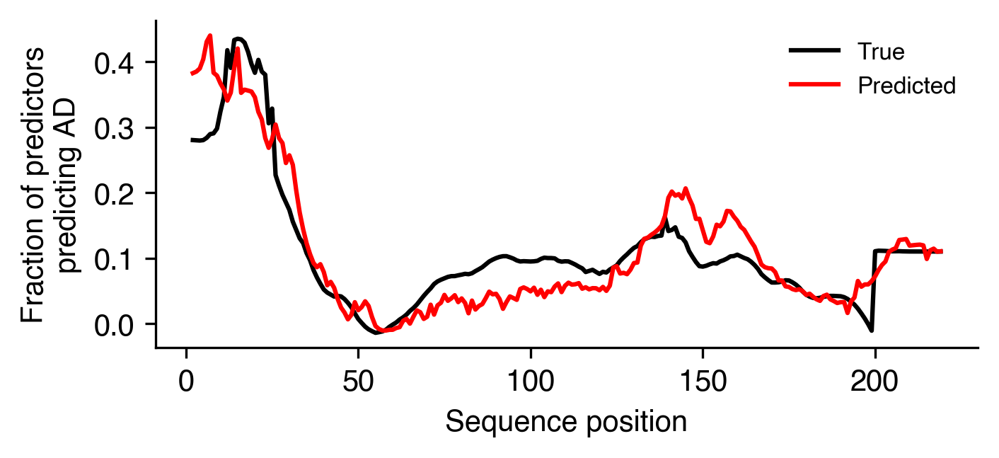

In [12]:
plt.subplots(1, 1, figsize=(5, 2))
i=36
plt.plot(all_six_regression_true_df.iloc[i, 2:1443].dropna(), color='black', label='True')
plt.plot(all_six_regression_pred_df.iloc[i, 2:1443].dropna(), color='red', label='Predicted')
plt.legend(frameon=False, fontsize=8)

sns.despine()
plt.xlabel("Sequence position", fontsize=10)
plt.ylabel("Fraction of predictors\npredicting AD", fontsize=10)

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


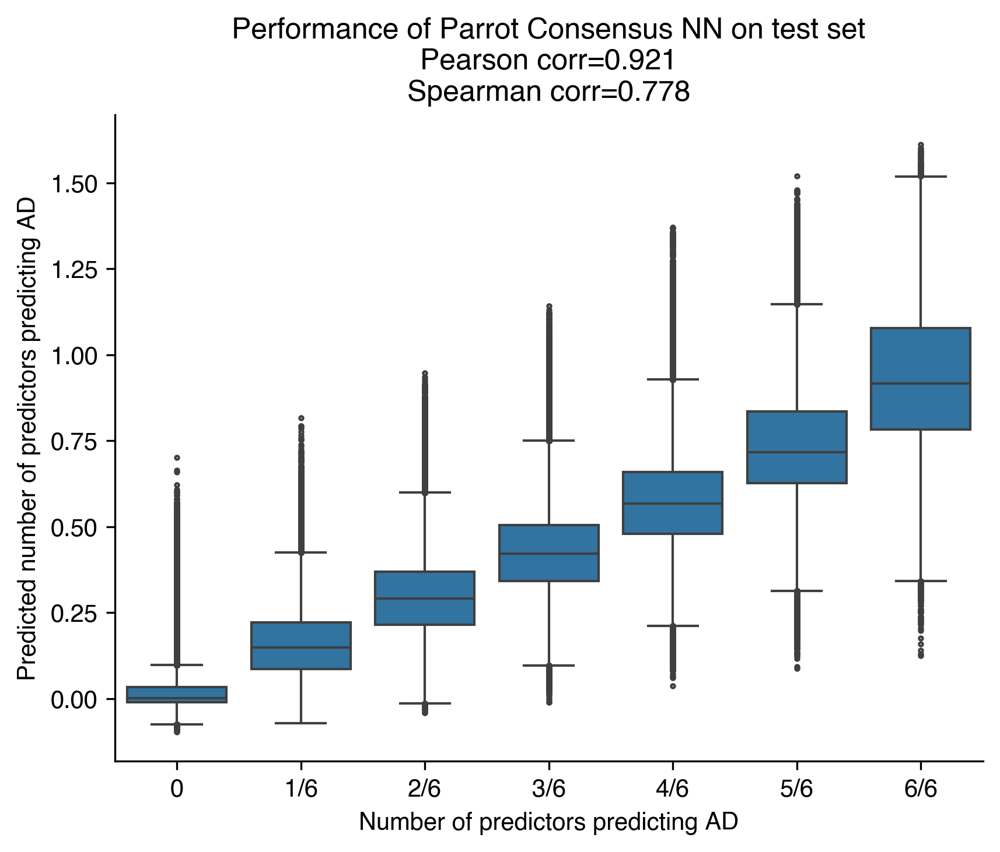

In [13]:
# Plotting performance on each residue in the test set - boxplot of predicted vs true values
sns.boxplot(x=all_six_true_vals_ls, y=all_six_pred_vals_ls,
           flierprops={"marker": ".", "markersize": 3, "color": "grey"})
sns.despine()
pearson_corr, pearson_p = pearsonr(all_six_true_vals_ls, all_six_pred_vals_ls)
spearman_corr, spearman_p = spearmanr(all_six_true_vals_ls, all_six_pred_vals_ls)
plt.title(f"Performance of Parrot Consensus NN on test set\nPearson corr={pearson_corr:.3}\nSpearman corr={spearman_corr:.3}")

plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
plt.xlabel("Number of predictors predicting AD")
plt.ylabel("Predicted number of predictors predicting AD")

plt.savefig("../figures/test_set_performance_all_six.pdf", format='pdf', bbox_inches='tight')
plt.savefig("../figures/all_combined_precision_recall.png", format='png', bbox_inches='tight')

Text(0, 0.5, 'Predicted AD score')

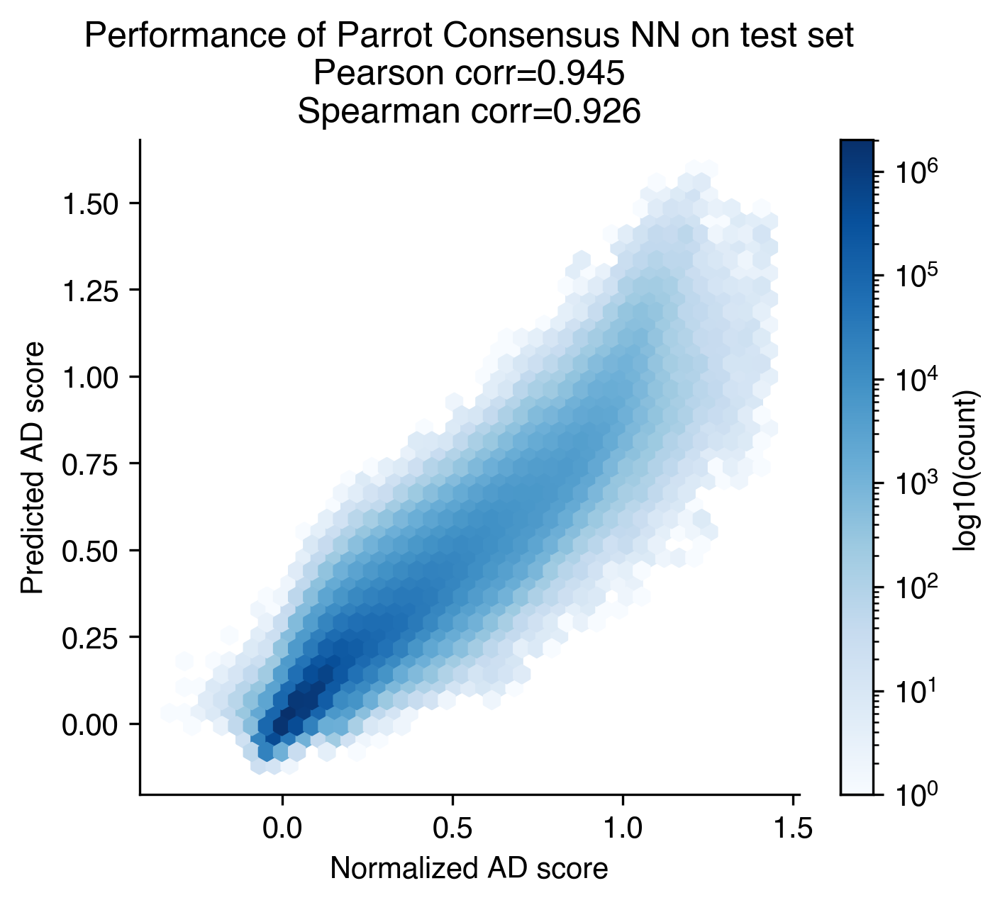

In [21]:
x = np.asarray(all_six_regression_true_vals_ls)
y = np.asarray(all_six_regression_pred_vals_ls)

fig, ax = plt.subplots(figsize=(5, 4))
hb = ax.hexbin(x, y, gridsize=40, bins='log', mincnt=1, cmap='Blues')
fig.colorbar(hb, ax=ax, label='log10(count)')
sns.despine()

pearson_corr, pearson_p = pearsonr(all_six_regression_true_vals_ls, all_six_regression_pred_vals_ls)
spearman_corr, spearman_p = spearmanr(all_six_regression_true_vals_ls, all_six_regression_pred_vals_ls)
plt.title(f"Performance of Parrot Consensus NN on test set\nPearson corr={pearson_corr:.3}\nSpearman corr={spearman_corr:.3}")

# plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
plt.xlabel("Normalized AD score")
plt.ylabel("Predicted AD score")

In [22]:
def round_to_interval(value, interval):
    return round(value / interval) * interval

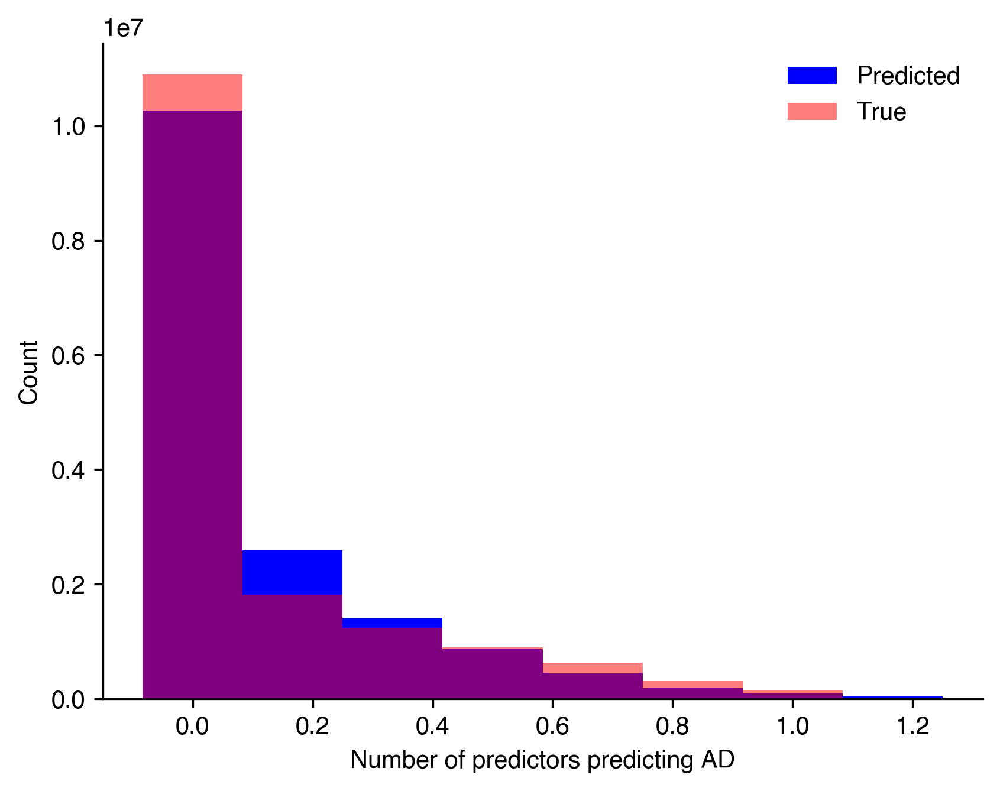

In [23]:
plt.hist(all_six_pred_vals_ls, bins=np.arange(-1/12, 8/6, 1/6), label='Predicted', color='blue')
plt.hist(all_six_true_vals_ls, bins=np.arange(-1/12, 8/6, 1/6), alpha=0.5, label='True', color='red')
plt.legend(frameon=False)
plt.xlabel("Number of predictors predicting AD")
plt.ylabel("Count")
sns.despine()

In [103]:
# Round the predicted values to the nearest 1/6 interval, so that we can compare as if it was classification
all_six_rounded_pred_ls = [round_to_interval(v, 1/6) for v in all_six_pred_vals_ls]

cm = confusion_matrix([f"{v:.2f}" for v in all_six_true_vals_ls],
    [f"{v:.2f}" for v in all_six_rounded_pred_ls])

In [13]:
# Looking at the true values
pd.DataFrame({'data' : [f"{v:.2f}" for v in all_six_true_vals_ls]}).value_counts()

data
0.00    10860723
0.17     1809604
0.33     1237360
0.50      879247
0.67      611569
0.83      309403
1.00      148976
Name: count, dtype: int64

In [14]:
# Looking at the predicted values
pd.DataFrame({'data' : [f"{v:.2f}" for v in all_six_rounded_pred_ls]}).value_counts()

data 
0.00     10218945
0.17      2571351
0.33      1382862
0.50       863723
0.67       472341
0.83       198873
1.00        92982
1.17        41413
1.33        12440
1.50         1889
1.67           50
-0.17          13
Name: count, dtype: int64

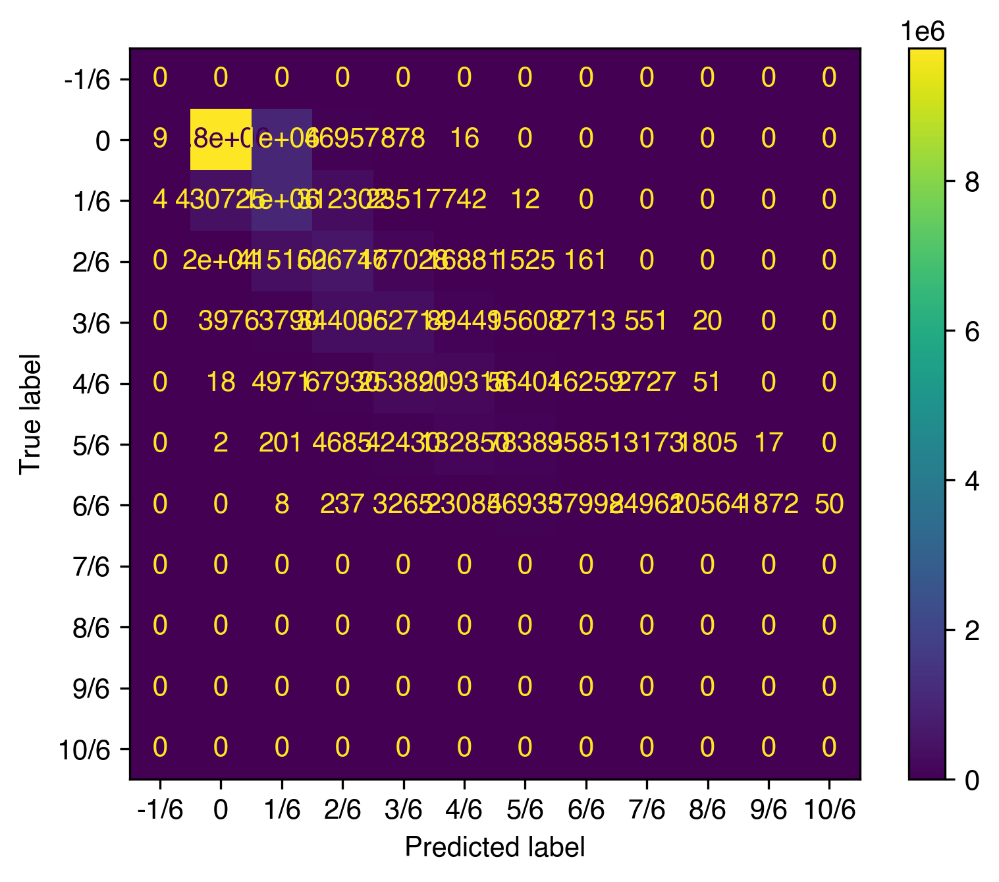

In [15]:
# Labels are from value_counts
labels = [f"{v:.2f}" for v in [-1/6, 0, 1/6, 2/6, 3/6, 4/6, 5/6, 6/6, 7/6, 8/6, 9/6, 10/6]]  # Orders must match the values in pred/true lists

cm = confusion_matrix(
    [f"{v:.2f}" for v in all_six_true_vals_ls],
    [f"{v:.2f}" for v in all_six_rounded_pred_ls],
    labels=labels  # ensures correct ordering
)

labels = ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"]  # We want displayed orders to be pretty
ConfusionMatrixDisplay(cm, display_labels=labels).plot()

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


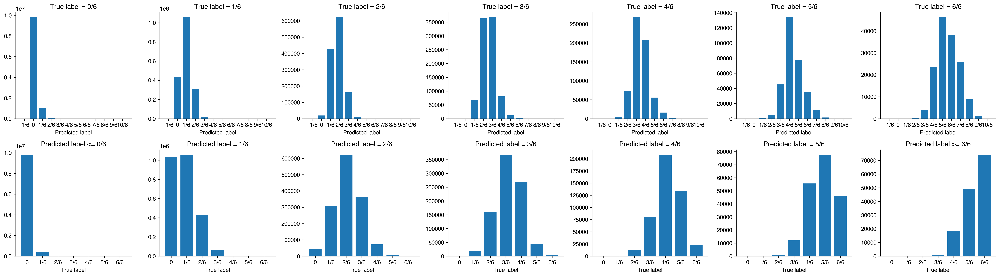

In [105]:
fig, axs = plt.subplots(2, 7, figsize=(25, 7))

# cm[0] is true = -1/6, which doesn't exists in the true values 
axs[0, 0].bar(x=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], height=cm[1])
axs[0, 0].set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"])
axs[0, 0].set_xlabel("Predicted label")
axs[0, 0].set_title("True label = 0/6")

axs[0, 1].bar(x=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], height=cm[2])
axs[0, 1].set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"])
axs[0, 1].set_xlabel("Predicted label")
axs[0, 1].set_title("True label = 1/6")

axs[0, 2].bar(x=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], height=cm[3])
axs[0, 2].set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"])
axs[0, 2].set_xlabel("Predicted label")
axs[0, 2].set_title("True label = 2/6")

axs[0, 3].bar(x=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], height=cm[4])
axs[0, 3].set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"])
axs[0, 3].set_xlabel("Predicted label")
axs[0, 3].set_title("True label = 3/6")

axs[0, 4].bar(x=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], height=cm[5])
axs[0, 4].set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"])
axs[0, 4].set_xlabel("Predicted label")
axs[0, 4].set_title("True label = 4/6")

axs[0, 5].bar(x=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], height=cm[6])
axs[0, 5].set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"])
axs[0, 5].set_xlabel("Predicted label")
axs[0, 5].set_title("True label = 5/6")

axs[0, 6].bar(x=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], height=cm[7])
axs[0, 6].set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11], ["-1/6", "0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6", "7/6", "8/6", "9/6", "10/6"])
axs[0, 6].set_xlabel("Predicted label")
axs[0, 6].set_title("True label = 6/6")


# For true predicted labels, what is truth? 
axs[1, 0].bar(x=[0, 1, 2, 3, 4, 5, 6], height=cm[1:8, 0:2].sum(axis=1)) # Combine -1 and 1
axs[1, 0].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6"])
axs[1, 0].set_xlabel("True label")
axs[1, 0].set_title("Predicted label <= 0/6")

axs[1, 1].bar(x=[0, 1, 2, 3, 4, 5, 6], height=cm[1:8, 2])
axs[1, 1].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6"])
axs[1, 1].set_xlabel("True label")
axs[1, 1].set_title("Predicted label = 1/6")

axs[1, 2].bar(x=[0, 1, 2, 3, 4, 5, 6], height=cm[1:8, 3])
axs[1, 2].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6"])
axs[1, 2].set_xlabel("True label")
axs[1, 2].set_title("Predicted label = 2/6")

axs[1, 3].bar(x=[0, 1, 2, 3, 4, 5, 6], height=cm[1:8, 4])
axs[1, 3].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6"])
axs[1, 3].set_xlabel("True label")
axs[1, 3].set_title("Predicted label = 3/6")

axs[1, 4].bar(x=[0, 1, 2, 3, 4, 5, 6], height=cm[1:8, 5])
axs[1, 4].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6"])
axs[1, 4].set_xlabel("True label")
axs[1, 4].set_title("Predicted label = 4/6")

axs[1, 5].bar(x=[0, 1, 2, 3, 4, 5, 6], height=cm[1:8, 6])
axs[1, 5].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6"])
axs[1, 5].set_xlabel("True label")
axs[1, 5].set_title("Predicted label = 5/6")

axs[1, 6].bar(x=[0, 1, 2, 3, 4, 5, 6], height=cm[1:8, 7:].sum(axis=1)) # Combine everything above 6/6
axs[1, 6].set_xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", "6/6"])
axs[1, 6].set_xlabel("True label")
axs[1, 6].set_title("Predicted label >= 6/6")

fig.tight_layout()
sns.despine()

plt.savefig("../figures/confusion_matrix_as_barplots.pdf", format='pdf', bbox_inches='tight')
plt.show()

# On test seqs

In [24]:
experimental = pd.read_csv('screen_test_seqs_with_activities.csv', index_col=0)

# Don't use hummel or arnold for regression tests so drop them
experimental = experimental[~experimental['screen'].isin(['hummel', 'arnold'])].reset_index(drop=True)

In [25]:
experimental['length'] = experimental['protein sequence']

In [26]:
# Look at which sequences we can run the predictors on
experimental['length'] = experimental['protein sequence'].apply(len)
experimental[['length', 'screen']].value_counts()

length  screen  
20      ravarani    27093
40      arf          9056
53      sanborn      4674
30      sanborn      3614
80      delrosso      804
Name: count, dtype: int64

In [27]:
# Missing Sog1, missing synthetics, can't actually use synthetics because used to train ADHunterEnsemble
experimental['screen'].value_counts()

screen
ravarani    27093
arf          9056
sanborn      8288
delrosso      804
Name: count, dtype: int64

In [28]:
synthetic_TF = 'MGTVSKGEEDNMAIIKEFMRFKVHMEGSVNGHEFEIEGEGEGRPYEGTQTAKLKVTKGGPLPFAWDILSPQFMYGSKAYVKHPADIPDYLKLSFPEGFKWERVMNFEDGGVVTVTQDSSLQDGEFIYKVKLRGTNFPSDGPVMQKKTMGWEASSERMYPEDGALKGEIKQRLKLKDGGHYDAEVKTTYKAKKPVQLPGAYNVNIKLDITSHNEDYTIVEQYERAEGRHSTGGMDELYKGTRPYACPVESCDRRFSRSDELTRHIRIHTGQKPFQCRICMRNFSRSDHLTTHIRTHTGEKPFACDICGRKFARSDERKRHTKIHTGPAAASTLEDPSAGDMRAANLWPSPLMIKRSKKNSLALSLTADQMVSALLDAEPPILYSEYDPTRPFSEASMMGLLTNLADRELVHMINWAKRVPGFVDLTLHDQVHLLECAWLEILMIGLVWRSMEHPVKLLFAPNLLLDRNQGKCVEGMVEIFDMLLATSSRFRMMNLQGEEFVCLKSIILLNSGVYTFLSSTLKSLEEKDHIHRVLDKITDTLIHLMAKAGLTLQQQHQRLAQLLLILSHIRHMSNKGMEHLYSMKCKNVVPLYDLLLEMLDAHRLHAPTSRGGASVEETDQSHLATAGSTSSAS'

In [29]:
# To get the ravarani preceeding sequences: 
# Added AD to a truncated HSF1 protein, truncated after amino acid 493

hsf1 = 'MNNAANTGTTNESNVSDAPRIEPLPSLNDDDIEKILQPNDIFTTDRTDASTTSSTAIEDIINPSLDPQSAASPVPSSSFFHDSRKPSTSTHLVRRGTPLGIYQTNLYGHNSRENTNPNSTLLSSKLLAHPPVPYGQNPDLLQHAVYRAQPSSGTTNAQPRQTTRRYQSHKSRPAFVNKLWSMLNDDSNTKLIQWAEDGKSFIVTNREEFVHQILPKYFKHSNFASFVRQLNMYGWHKVQDVKSGSIQSSSDDKWQFENENFIRGREDLLEKIIRQKGSSNNHNSPSGNGNPANGSNIPLDNAAGSNNSNNNISSSNSFFNNGHLLQGKTLRLMNEANLGDKNDVTAILGELEQIKYNQIAISKDLLRINKDNELLWQENMMARERHRTQQQALEKMFRFLTSIVPHLDPKMIMDGLGDPKVNNEKLNSANNIGLNRDNTGTIDELKSNDSFINDDRNSFTNATTNARNNMSPNNDDNSIDTASTNTTNRKKNIDENIKNNNDIINDIIFNTNLANNLSNYNSNNNAGSPIRPYKQRYLLKNRANSSTSSENPSLTPFDIESNNDRKISEIPFDDEEEEETDFRPFTSRDPNNQTSENTFDPNRFTMLSDDDLKKDSHTNDNKHNESDLFWDNVHRNIDEQDARLQNLENMVHILSPGYPNKSFNNKTSSTNTNSNMESAVNVNSPGFNLQDYLTGESNSPNSVHSVPSNGSGSTPLPMPNDNDTEHASTSVNQGENGSGLTPFLTVDDHTLNDNNTSEGSTRVSPDIKFSATENTKVSDNLPSFNDHSYSTQADTAPENAKKRFVEEIPEPAIVEIQDPTEYNDHRLPKRAKK'

prefix_ravarani_40mer = hsf1[473:493]
prefix_ravarani_53mer = hsf1[460:493]

# This prefix is the same as we use for our sequences
prefix_arf_53mer = synthetic_TF[-13:] #'SHLATAGSTSSAS'

# Need prefix for sanborn 30mers 
prefix_sanborn_40mer = synthetic_TF[-10:] #'ATAGSTSSAS'
prefix_sanborn_53mer = synthetic_TF[-23:] #'GGASVEETDQSHLATAGSTSSAS'

In [30]:
prefix_arf_53mer == 'SHLATAGSTSSAS'

True

In [31]:
len(prefix_arf_53mer) + 40
len(prefix_sanborn_40mer) + 30

40

In [32]:
experimental[['length', 'screen']].value_counts()

length  screen  
20      ravarani    27093
40      arf          9056
53      sanborn      4674
30      sanborn      3614
80      delrosso      804
Name: count, dtype: int64

In [39]:
# Now we need to write every sequence with the correct prefix
# Writing them as >= 53 length for PADDLE and ADHunterEnsemble

with open('test_seqs_53mers.fasta', 'w+') as f:
    for screen, group in experimental.groupby('screen'): 
        if screen == 'ravarani': 
            for i in group.index:
                f.write(">" + group.loc[i, 'id'] + '\n')
                f.write(prefix_ravarani_53mer + group.loc[i, 'protein sequence'] + '\n')
        elif screen == 'arf': 
            for i in group.index:
                f.write(">" + group.loc[i, 'id'] + '\n')
                f.write(prefix_arf_53mer + group.loc[i, 'protein sequence'] + '\n')
        elif screen == 'sanborn': 
            for i in group.index:
                # Short sanborn seqs
                if group.loc[i, 'length'] == 30: 
                    f.write(">" + group.loc[i, 'id'] + '\n')
                    f.write(prefix_sanborn_53mer + group.loc[i, 'protein sequence'] + '\n')
                # Normal length sanborn seqs
                else: 
                    f.write(">" + group.loc[i, 'id'] + '\n')
                    f.write(group.loc[i, 'protein sequence'] + '\n')
        elif screen == 'delrosso': 
            for i in group.index:
                f.write(">" + group.loc[i, 'id']+ '\n')
                f.write(group.loc[i, 'protein sequence'] + '\n')

In [33]:
# Sanjana has already filtered duplicate sequences :) 
experimental.drop_duplicates(subset=['protein sequence'])

,id,protein sequence,activity,screen,length
0,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSN,0.132163,arf,40
1,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,TAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFASLSS,0.698559,arf,40
2,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS,1.002289,arf,40
3,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,DSTFHPLSSNIDPTFASLSSNLNPTPLTSSMPRPTNPFQG,0.216912,arf,40
4,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,IDPTFASLSSNLNPTPLTSSMPRPTNPFQGLPDYHVPAGI,-0.182901,arf,40
...,...,...,...,...,...
45236,delrosso_ZSCAN23_231_310,DREGRLEKQRVSSSVERPYICSECGKSFTQNSILIEHQRTHTGEKP...,3.165414,delrosso,80
45237,delrosso_ZSCAN23_251_330,CSECGKSFTQNSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQ...,4.400658,delrosso,80
45238,delrosso_ZSCAN23_261_340,NSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQRLHTGEKRYQ...,4.113329,delrosso,80
45239,delrosso_ZSCAN23_281_360,ECGRAFSQRSGLFQHQRLHTGEKRYQCSVCGKAFSQNAGLFHHLRI...,-0.541223,delrosso,80


In [40]:
# Now we need to write every sequence with the correct prefix
# Writing them as >= 40 length for ADhunterLite, TADA, ADpred

with open('test_seqs_40mers.fasta', 'w+') as f:
    for screen, group in experimental.groupby('screen'): 
        if screen == 'ravarani': 
            for i in group.index:
                f.write(">" + group.loc[i, 'id'] + "\n")
                f.write(prefix_ravarani_40mer + group.loc[i, 'protein sequence'] + '\n')
        elif screen == 'arf': 
            for i in group.index:
                f.write(">" + group.loc[i, 'id'] + "\n")
                f.write(group.loc[i, 'protein sequence'] + '\n')
        elif screen == 'sanborn': 
            for i in group.index:
                # Short sanborn seqs
                if group.loc[i, 'length'] == 30: 
                    f.write(">" + group.loc[i, 'id'] + "\n")
                    f.write(prefix_sanborn_40mer + group.loc[i, 'protein sequence'] + '\n')
                # Normal length sanborn seqs
                else: 
                    f.write(">" + group.loc[i, 'id'] + "\n")
                    f.write(group.loc[i, 'protein sequence'] + '\n')
        elif screen == 'delrosso': 
            for i in group.index:
                f.write(">" + group.loc[i, 'id'] + "\n")
                f.write(group.loc[i, 'protein sequence'] + '\n')

In [34]:
def read_fasta(file): 
    """
    Reads in a fasta file and returns a pandas dataframe with columns "name" and "seq"
    """
    with open(file, 'r') as f:
        lines = f.readlines()

    seq = ""
    names = []
    seqs = []

    for line in lines:
        if line.startswith(">"): 
            names.append(line.strip().replace(">", ''))
            if len(names) > 1: 
                seqs.append(seq)
                seq = ""
        else: 
            seq += line.strip()
    
    seqs.append(seq)

    return pd.DataFrame({'name' : names, 'seq' : seqs})

In [119]:
with open('all_test_seqs.tsv', 'w+') as f:
    for i in experimental.index: 
        f.write(experimental.loc[i, 'id'].replace(" ", "___").replace('\xa0', '___') + '\t' + experimental.loc[i, 'protein sequence'] + '\n')

In [45]:
# Read in individual predictions and merge with experimental df 
paddle_preds = pd.read_csv('test_seqs/test_seqs_53mers_Paddle_preds_dask.csv', index_col=0, converters={'paddle_preds' : ast.literal_eval})
paddle_preds = paddle_preds.rename(columns={'sequence' : 'paddle_sequence'})

adhunter_ensemble_preds = pd.read_csv('test_seqs/test_seqs_53mers_adhunter_ensemble_preds.csv', index_col=0, converters={'adhunter_ensemble_preds' : ast.literal_eval})
adhunter_ensemble_preds = adhunter_ensemble_preds.rename(columns={'sequence' : 'adhunter_ensemble_sequence'})

adhunter_lite_preds = pd.read_csv('test_seqs/test_seqs_40mers_ADHunter_preds_dask.csv', index_col=0, converters={'adhunter_preds' : ast.literal_eval})
adhunter_lite_preds = adhunter_lite_preds.rename(columns={'sequence' : 'adhunter_lite_sequence'})

tada_preds = pd.read_csv('test_seqs/test_seqs_40mers_TADA_preds_dask.csv', index_col=0, converters={'tada_preds' : ast.literal_eval})
tada_preds = tada_preds.rename(columns={'sequence' : 'tada_sequence'})

adpred_preds = pd.read_csv('test_seqs/test_seqs_53mers_ADpred_preds_dask.csv', index_col=0, converters={'adpred_preds' : ast.literal_eval})
adpred_preds = adpred_preds.rename(columns={'sequence' : 'adpred_sequence'})

merged_experimental_pred_v1 = experimental.merge(paddle_preds, right_on='name', left_on='id').merge(adhunter_ensemble_preds, on='name').merge(adhunter_lite_preds, on='name').merge(tada_preds, on='name').merge(adpred_preds, on='name')

In [46]:
# Check that nothing was lost in the merge - all ids should be the same
set(merged_experimental_pred_v1['id']).difference(experimental['id'])

set()

In [37]:
parrot_preds_all_six = read_parrot_preds('test_seqs/test_preds_parrot_all_six_model.csv')
parrot_preds_all_six

,name,sequence,preds
0,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSN,"[-0.01616593, -0.022775516, -0.019543022, -0.0..."
1,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,TAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFASLSS,"[0.04921867, 0.062188726, 0.05316156, 0.076544..."
2,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS,"[0.33903167, 0.38685003, 0.3885377, 0.40224245..."
3,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,DSTFHPLSSNIDPTFASLSSNLNPTPLTSSMPRPTNPFQG,"[0.1304363, 0.07550646, 0.08181511, 0.08332826..."
4,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,IDPTFASLSSNLNPTPLTSSMPRPTNPFQGLPDYHVPAGI,"[0.04826602, 0.023021447, 0.009377006, 0.01133..."
...,...,...,...
45236,delrosso_ZSCAN23_231_310,DREGRLEKQRVSSSVERPYICSECGKSFTQNSILIEHQRTHTGEKP...,"[-0.011648637, -0.024875429, -0.03578237, -0.0..."
45237,delrosso_ZSCAN23_251_330,CSECGKSFTQNSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQ...,"[-0.016542308, -0.020021643, -0.01585827, -0.0..."
45238,delrosso_ZSCAN23_261_340,NSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQRLHTGEKRYQ...,"[-0.0025178585, -0.0044553485, -0.02335376, -0..."
45239,delrosso_ZSCAN23_281_360,ECGRAFSQRSGLFQHQRLHTGEKRYQCSVCGKAFSQNAGLFHHLRI...,"[-0.0032836925, -0.012000094, -0.026098043, -0..."


In [39]:
parrot_preds_all_six_regression = read_parrot_preds('test_seqs/test_preds_parrot_all_six_model_regression.csv')
parrot_preds_all_six_regression

,name,sequence,preds
0,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSN,"[0.1085782, 0.11055821, 0.11091558, 0.10999788..."
1,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,TAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFASLSS,"[0.13364373, 0.1438776, 0.14202496, 0.1737737,..."
2,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS,"[0.3081621, 0.3948678, 0.38305357, 0.40646, 0...."
3,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,DSTFHPLSSNIDPTFASLSSNLNPTPLTSSMPRPTNPFQG,"[0.24597827, 0.22093552, 0.2308225, 0.23881996..."
4,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,IDPTFASLSSNLNPTPLTSSMPRPTNPFQGLPDYHVPAGI,"[0.18617702, 0.16782929, 0.14385022, 0.1527354..."
...,...,...,...
45236,delrosso_ZSCAN23_231_310,DREGRLEKQRVSSSVERPYICSECGKSFTQNSILIEHQRTHTGEKP...,"[0.100276306, 0.106948175, 0.09483471, 0.10937..."
45237,delrosso_ZSCAN23_251_330,CSECGKSFTQNSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQ...,"[0.10798811, 0.097531654, 0.09591884, 0.112087..."
45238,delrosso_ZSCAN23_261_340,NSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQRLHTGEKRYQ...,"[0.10406408, 0.10762325, 0.10621995, 0.1094609..."
45239,delrosso_ZSCAN23_281_360,ECGRAFSQRSGLFQHQRLHTGEKRYQCSVCGKAFSQNAGLFHHLRI...,"[0.10414207, 0.11983683, 0.10771792, 0.1108049..."


In [40]:
test_data_parrot = experimental.merge(parrot_preds_all_six, left_on='protein sequence', right_on='sequence')
test_data_parrot

,id,protein sequence,activity,screen,length,name,sequence,preds
0,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSN,0.132163,arf,40,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,VVSTIPSVQLTAFSPAKKKLRLSPHLDFPIDSTFHPLSSN,"[-0.01616593, -0.022775516, -0.019543022, -0.0..."
1,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,TAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFASLSS,0.698559,arf,40,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,TAFSPAKKKLRLSPHLDFPIDSTFHPLSSNIDPTFASLSS,"[0.04921867, 0.062188726, 0.05316156, 0.076544..."
2,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS,1.002289,arf,40,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,RLSPHLDFPIDSTFHPLSSNIDPTFASLSSNLNPTPLTSS,"[0.33903167, 0.38685003, 0.3885377, 0.40224245..."
3,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,DSTFHPLSSNIDPTFASLSSNLNPTPLTSSMPRPTNPFQG,0.216912,arf,40,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,DSTFHPLSSNIDPTFASLSSNLNPTPLTSSMPRPTNPFQG,"[0.1304363, 0.07550646, 0.08181511, 0.08332826..."
4,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,IDPTFASLSSNLNPTPLTSSMPRPTNPFQGLPDYHVPAGI,-0.182901,arf,40,arf_evm_27.TU.AmTr_v1.0_scaffold00148.24|evm_2...,IDPTFASLSSNLNPTPLTSSMPRPTNPFQGLPDYHVPAGI,"[0.04826602, 0.023021447, 0.009377006, 0.01133..."
...,...,...,...,...,...,...,...,...
45236,delrosso_ZSCAN23_231_310,DREGRLEKQRVSSSVERPYICSECGKSFTQNSILIEHQRTHTGEKP...,3.165414,delrosso,80,delrosso_ZSCAN23_231_310,DREGRLEKQRVSSSVERPYICSECGKSFTQNSILIEHQRTHTGEKP...,"[-0.011648637, -0.024875429, -0.03578237, -0.0..."
45237,delrosso_ZSCAN23_251_330,CSECGKSFTQNSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQ...,4.400658,delrosso,80,delrosso_ZSCAN23_251_330,CSECGKSFTQNSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQ...,"[-0.016542308, -0.020021643, -0.01585827, -0.0..."
45238,delrosso_ZSCAN23_261_340,NSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQRLHTGEKRYQ...,4.113329,delrosso,80,delrosso_ZSCAN23_261_340,NSILIEHQRTHTGEKPYECDECGRAFSQRSGLFQHQRLHTGEKRYQ...,"[-0.0025178585, -0.0044553485, -0.02335376, -0..."
45239,delrosso_ZSCAN23_281_360,ECGRAFSQRSGLFQHQRLHTGEKRYQCSVCGKAFSQNAGLFHHLRI...,-0.541223,delrosso,80,delrosso_ZSCAN23_281_360,ECGRAFSQRSGLFQHQRLHTGEKRYQCSVCGKAFSQNAGLFHHLRI...,"[-0.0032836925, -0.012000094, -0.026098043, -0..."


In [47]:
merged_experimental_pred = merged_experimental_pred_v1.merge(parrot_preds_all_six, left_on=['protein sequence'], right_on=['sequence'])
merged_experimental_pred_regression = merged_experimental_pred_v1.merge(parrot_preds_all_six_regression, left_on=['protein sequence'], right_on=['sequence'])

In [48]:
# test_data['max_value'] = [max(ast.literal_eval(ls)) for ls in (test_data['combined_preds'])]

merged_experimental_pred['paddle_max_value'] = [max(ls) for ls in (merged_experimental_pred['paddle_preds'])]
merged_experimental_pred['paddle_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred['paddle_preds'])]

merged_experimental_pred['tada_max_value'] = [max(ls) for ls in (merged_experimental_pred['tada_preds'])]
merged_experimental_pred['tada_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred['tada_preds'])]

merged_experimental_pred['adpred_max_value'] = [max(ls) for ls in (merged_experimental_pred['adpred_preds'])]
merged_experimental_pred['adpred_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred['adpred_preds'])]

merged_experimental_pred['adhunter_max_value'] = [max(ls) for ls in (merged_experimental_pred['adhunter_preds'])]
merged_experimental_pred['adhunter_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred['adhunter_preds'])]

merged_experimental_pred['adhunter_ensemble_max_value'] = [max(ls) for ls in (merged_experimental_pred['adhunter_ensemble_preds'])]
merged_experimental_pred['adhunter_ensemble_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred['adhunter_ensemble_preds'])]

merged_experimental_pred['parrot_max_value_all_six'] = [max([float(a) for a in ls]) for ls in (merged_experimental_pred['preds'])]
merged_experimental_pred['parrot_mean_value_all_six'] = [np.mean([float(a) for a in ls]) for ls in (merged_experimental_pred['preds'])]

In [49]:
# test_data['max_value'] = [max(ast.literal_eval(ls)) for ls in (test_data['combined_preds'])]

merged_experimental_pred_regression['paddle_max_value'] = [max(ls) for ls in (merged_experimental_pred_regression['paddle_preds'])]
merged_experimental_pred_regression['paddle_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred_regression['paddle_preds'])]

merged_experimental_pred_regression['tada_max_value'] = [max(ls) for ls in (merged_experimental_pred_regression['tada_preds'])]
merged_experimental_pred_regression['tada_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred_regression['tada_preds'])]

merged_experimental_pred_regression['adpred_max_value'] = [max(ls) for ls in (merged_experimental_pred_regression['adpred_preds'])]
merged_experimental_pred_regression['adpred_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred_regression['adpred_preds'])]

merged_experimental_pred_regression['adhunter_max_value'] = [max(ls) for ls in (merged_experimental_pred_regression['adhunter_preds'])]
merged_experimental_pred_regression['adhunter_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred_regression['adhunter_preds'])]

merged_experimental_pred_regression['adhunter_ensemble_max_value'] = [max(ls) for ls in (merged_experimental_pred_regression['adhunter_ensemble_preds'])]
merged_experimental_pred_regression['adhunter_ensemble_mean_value'] = [np.mean(ls) for ls in (merged_experimental_pred_regression['adhunter_ensemble_preds'])]

merged_experimental_pred_regression['parrot_max_value_all_six'] = [max([float(a) for a in ls]) for ls in (merged_experimental_pred_regression['preds'])]
merged_experimental_pred_regression['parrot_mean_value_all_six'] = [np.mean([float(a) for a in ls]) for ls in (merged_experimental_pred_regression['preds'])]

In [51]:
test_data_parrot['parrot_max_value_all_six'] = [max([float(a) for a in ls]) for ls in (test_data_parrot['preds'])]
test_data_parrot['parrot_mean_value_all_six'] = [np.mean([float(a) for a in ls]) for ls in (test_data_parrot['preds'])]

# test_data_parrot_regression['parrot_max_value_all_six'] = [max([float(a) for a in ls]) for ls in (test_data_parrot_regression['preds'])]
# test_data_parrot_regression['parrot_mean_value_all_six'] = [np.mean([float(a) for a in ls]) for ls in (test_data_parrot_regression['preds'])]

In [52]:
color_dict = {
    'tada' : 'green', 
    'adpred' : 'lightblue',
    'adhunter_ensemble' : 'red',
    'adhunter' : 'orange', 
    'paddle' : 'purple' 
}

def make_scatterplot(screen):
    fig, axs = plt.subplots(2, 6, figsize=(15, 5))

    for i, col in enumerate(['paddle', 'tada', 'adpred', 'adhunter', 'adhunter_ensemble']): 
        axs[0, i].scatter(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'{col}_max_value'], 
                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'], 
                        alpha=0.2, 
                        s=5,
                        color=color_dict[col])

        pearson_corr, pearson_p = pearsonr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'{col}_max_value'], 
                                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
        spearman_corr, spearman_p = spearmanr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'{col}_max_value'], 
                                            merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
        axs[0, i].set_xlabel(f'{col}_max_value')
        axs[0, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

        axs[1, i].scatter(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'{col}_mean_value'], 
                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'],
                        alpha=0.2,
                        s=5,
                        color=color_dict[col])
        pearson_corr, pearson_p = pearsonr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'{col}_mean_value'], 
                                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
        spearman_corr, spearman_p = spearmanr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'{col}_mean_value'], 
                                            merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
        axs[1, i].set_xlabel(f'{col}_mean_value')
        axs[1, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    # Parrot preds - all six
    axs[0, 5].scatter(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'parrot_max_value_all_six'], 
                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'], 
                        alpha=0.1, s=5,
                        color='grey')

    pearson_corr, pearson_p = pearsonr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'parrot_max_value_all_six'], 
                                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
    spearman_corr, spearman_p = spearmanr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'parrot_max_value_all_six'], 
                                            merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
    axs[0, 5].set_xlabel(f'parrot_pred_max_value\nall_six')
    axs[0, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

    axs[1, 5].scatter(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'parrot_mean_value_all_six'], 
                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'],
                        alpha=0.1, s=5,
                        color='grey')
    pearson_corr, pearson_p = pearsonr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'parrot_mean_value_all_six'], 
                                        merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
    spearman_corr, spearman_p = spearmanr(merged_experimental_pred[merged_experimental_pred['screen'] == screen][f'parrot_mean_value_all_six'], 
                                            merged_experimental_pred[merged_experimental_pred['screen'] == screen]['activity'])
    axs[1, 5].set_xlabel(f'parrot_pred_mean_value\nall_six')
    axs[1, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    fig.tight_layout()
    plt.savefig(f"../figures/{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
    plt.savefig(f"../figures/{screen}_scatter_plots.png", format='png', bbox_inches='tight')

In [53]:
color_dict = {
    'tada' : 'green', 
    'adpred' : 'lightblue',
    'adhunter_ensemble' : 'red',
    'adhunter' : 'orange', 
    'paddle' : 'purple' 
}

def make_scatterplot_regression(screen):
    fig, axs = plt.subplots(2, 6, figsize=(15, 5))

    for i, col in enumerate(['paddle', 'tada', 'adpred', 'adhunter', 'adhunter_ensemble']): 
        axs[0, i].scatter(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'{col}_max_value'], 
                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'], 
                        alpha=0.2, 
                        s=5,
                        color=color_dict[col])

        pearson_corr, pearson_p = pearsonr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'{col}_max_value'], 
                                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
        spearman_corr, spearman_p = spearmanr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'{col}_max_value'], 
                                            merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
        axs[0, i].set_xlabel(f'{col}_max_value')
        axs[0, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

        axs[1, i].scatter(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'{col}_mean_value'], 
                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'],
                        alpha=0.2,
                        s=5,
                        color=color_dict[col])
        pearson_corr, pearson_p = pearsonr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'{col}_mean_value'], 
                                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
        spearman_corr, spearman_p = spearmanr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'{col}_mean_value'], 
                                            merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
        axs[1, i].set_xlabel(f'{col}_mean_value')
        axs[1, i].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    # Parrot preds - all six
    axs[0, 5].scatter(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'parrot_max_value_all_six'], 
                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'], 
                        alpha=0.1, s=5,
                        color='grey')

    pearson_corr, pearson_p = pearsonr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'parrot_max_value_all_six'], 
                                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
    spearman_corr, spearman_p = spearmanr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'parrot_max_value_all_six'], 
                                            merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
    axs[0, 5].set_xlabel(f'parrot_pred_max_value\nall_six')
    axs[0, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")

    axs[1, 5].scatter(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'parrot_mean_value_all_six'], 
                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'],
                        alpha=0.1, s=5,
                        color='grey')
    pearson_corr, pearson_p = pearsonr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'parrot_mean_value_all_six'], 
                                        merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
    spearman_corr, spearman_p = spearmanr(merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen][f'parrot_mean_value_all_six'], 
                                            merged_experimental_pred_regression[merged_experimental_pred_regression['screen'] == screen]['activity'])
    axs[1, 5].set_xlabel(f'parrot_pred_mean_value\nall_six')
    axs[1, 5].set_title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")


    fig.tight_layout()
    plt.savefig(f"../figures/{screen}_scatter_plots.pdf", format='pdf', bbox_inches='tight')
    plt.savefig(f"../figures/{screen}_scatter_plots.png", format='png', bbox_inches='tight')

In [79]:
merged_experimental_pred.to_csv("test_seq_experimental_and_preds_w_parrot.csv")

## Delrosso

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


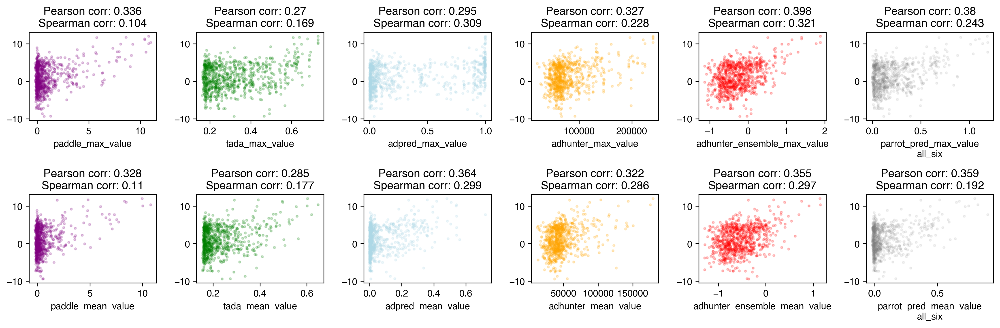

In [84]:
make_scatterplot('delrosso')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


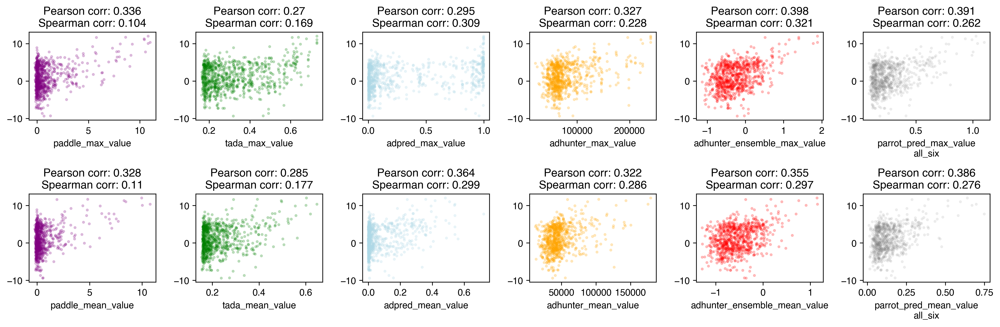

In [54]:
make_scatterplot_regression('delrosso')

# Ravarani scatter plots

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


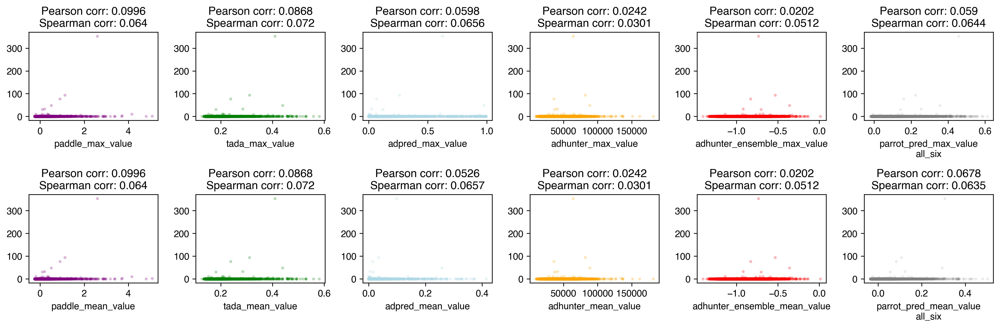

In [87]:
make_scatterplot('ravarani')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


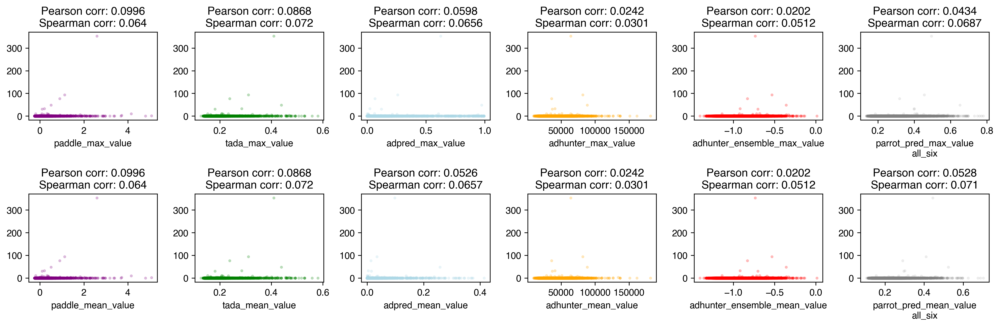

In [55]:
make_scatterplot_regression('ravarani')

# Sanborn scatter plots

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


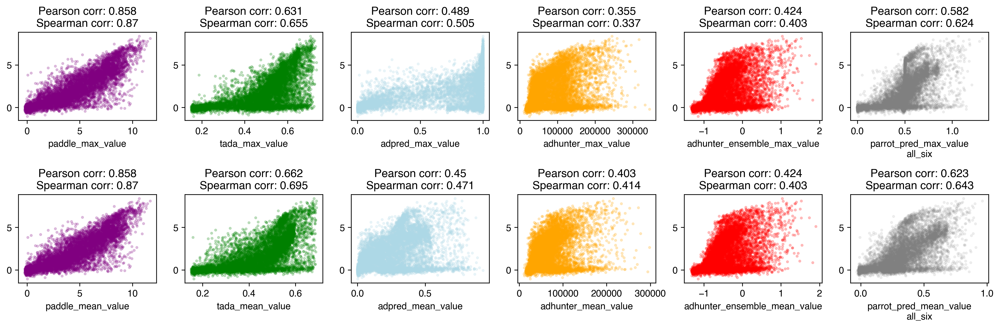

In [85]:
make_scatterplot('sanborn')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


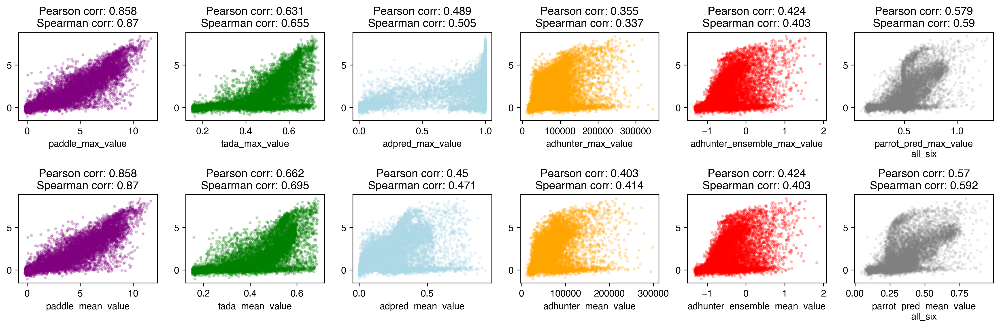

In [56]:
make_scatterplot_regression('sanborn')

# Morffy scatter plots

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


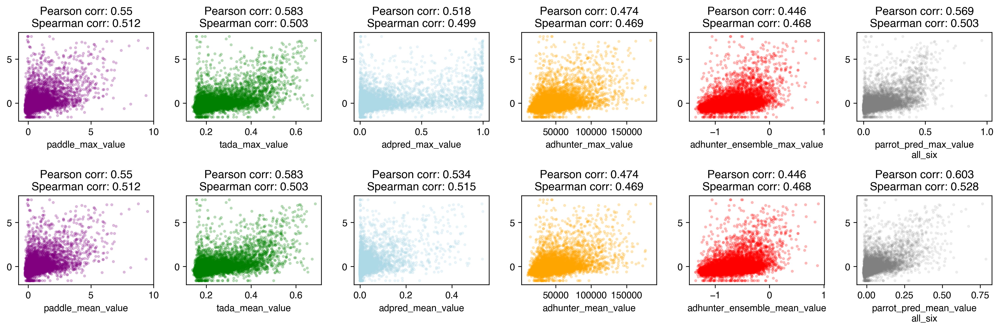

In [86]:
make_scatterplot('arf')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


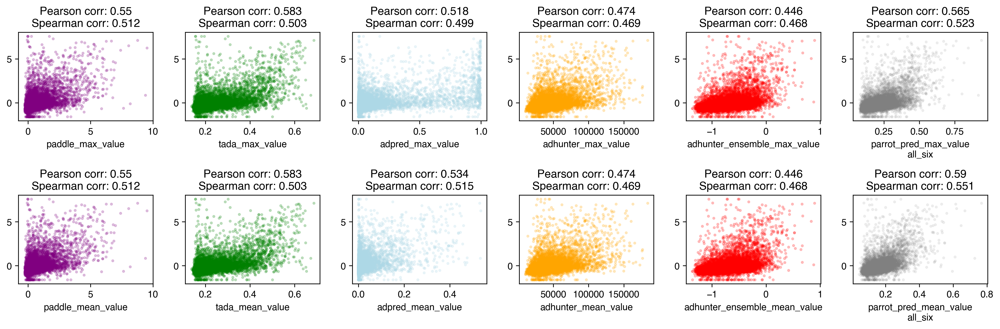

In [57]:
make_scatterplot_regression('arf')

# Other random code

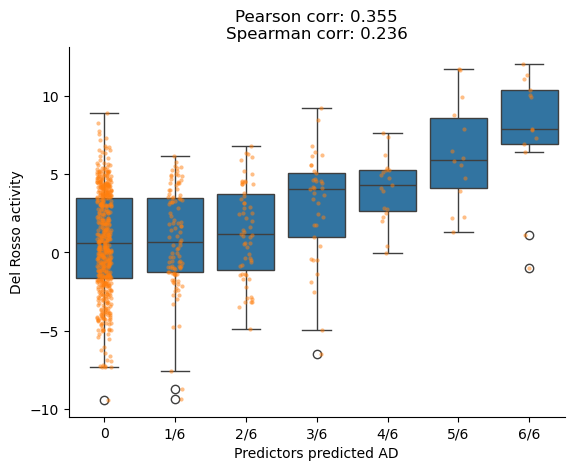

In [293]:
ax = sns.boxplot(x=test_data[test_data['screen'] == 'delrosso']['max_value'], y=test_data[test_data['screen'] == 'delrosso']['activity'])

pearson_corr, pearson_p = pearsonr(test_data[test_data['screen'] == 'delrosso']['max_value'], test_data[test_data['screen'] == 'delrosso']['activity'])
spearman_corr, spearman_p = spearmanr(test_data[test_data['screen'] == 'delrosso']['max_value'], test_data[test_data['screen'] == 'delrosso']['activity'])

sns.stripplot(data=test_data[test_data['screen'] == 'delrosso'], x='max_value', y='activity', 
              dodge=True, alpha=0.5, legend=False, ax=ax, size=3)

plt.title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")
plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
plt.xlabel("Predictors predicted AD")
plt.ylabel("Del Rosso activity")
sns.despine()

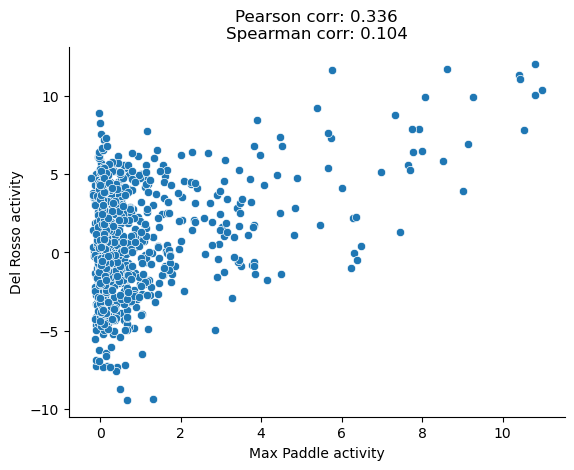

In [301]:
ax = sns.scatterplot(x=test_data[test_data['screen'] == 'delrosso']['paddle_max_value'], y=test_data[test_data['screen'] == 'delrosso']['activity'])

pearson_corr, pearson_p = pearsonr(test_data[test_data['screen'] == 'delrosso']['paddle_max_value'], test_data[test_data['screen'] == 'delrosso']['activity'])
spearman_corr, spearman_p = spearmanr(test_data[test_data['screen'] == 'delrosso']['paddle_max_value'], test_data[test_data['screen'] == 'delrosso']['activity'])

# sns.stripplot(data=test_data[test_data['screen'] == 'delrosso'], x='paddle_max_value', y='activity', 
#               dodge=True, alpha=0.5, legend=False, ax=ax, size=3)

plt.title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")
# plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
plt.xlabel("Max Paddle activity")
plt.ylabel("Del Rosso activity")
sns.despine()

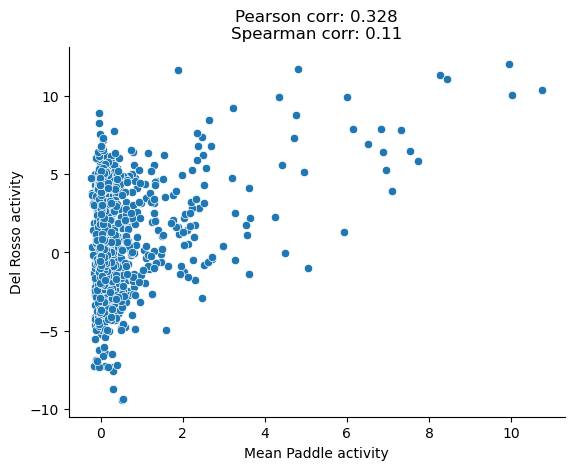

In [306]:
ax = sns.scatterplot(x=test_data[test_data['screen'] == 'delrosso']['paddle_mean_value'], y=test_data[test_data['screen'] == 'delrosso']['activity'])

pearson_corr, pearson_p = pearsonr(test_data[test_data['screen'] == 'delrosso']['paddle_mean_value'], test_data[test_data['screen'] == 'delrosso']['activity'])
spearman_corr, spearman_p = spearmanr(test_data[test_data['screen'] == 'delrosso']['paddle_mean_value'], test_data[test_data['screen'] == 'delrosso']['activity'])

# sns.stripplot(data=test_data[test_data['screen'] == 'delrosso'], x='paddle_max_value', y='activity', 
#               dodge=True, alpha=0.5, legend=False, ax=ax, size=3)

plt.title(f"Pearson corr: {pearson_corr:.3}\nSpearman corr: {spearman_corr:.3}")
# plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
plt.xlabel("Mean Paddle activity")
plt.ylabel("Del Rosso activity")
sns.despine()

In [288]:
test_data[(test_data['screen'] == 'delrosso') & (test_data['max_value'] >= 5/6)]

,id,protein sequence,activity,screen,name,sequence,adhunter_centers,adhunter_preds,tada_centers,tada_preds,...,adhunter_AD,tada_AD,paddle_AD,adhunter_ensemble_AD,adpred_AD,composition_AD,combined_has_AD,combined_has_AD_strict,combined_has_AD_medium,combined_has_AD_lenient
20689,delrosso_CREB3_1_80,MELELDAGDQDLLAFLLEESGDLGTAPDEAVRAPLDWALPLSEVPS...,7.771722,delrosso,61831,MELELDAGDQDLLAFLLEESGDLGTAPDEAVRAPLDWALPLSEVPS...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[104507.73,93418.914,93911.02,71902.0,93046.23...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.69319355,0.68266433,0.6407766,0.6354747,0.6...",...,True,True,True,True,True,True,True,True,True,True
20690,delrosso_CREB3_11_90,DLLAFLLEESGDLGTAPDEAVRAPLDWALPLSEVPSDWEVDDLLCS...,7.317027,delrosso,61832,DLLAFLLEESGDLGTAPDEAVRAPLDWALPLSEVPSDWEVDDLLCS...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[95313.74,60983.324,56803.633,57366.617,74509....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.6240114,0.6193587,0.62832034,0.62691844,0.6...",...,True,True,True,True,True,True,True,True,True,True
20691,delrosso_CREB3_21_100,GDLGTAPDEAVRAPLDWALPLSEVPSDWEVDDLLCSLLSPPASLNI...,-1.020130,delrosso,61833,GDLGTAPDEAVRAPLDWALPLSEVPSDWEVDDLLCSLLSPPASLNI...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[165482.4,157666.34,149944.42,140642.92,142104...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.6342775,0.6356459,0.63969827,0.6442631,0.65...",...,True,True,True,True,True,True,True,True,True,True
20692,delrosso_CREB3_31_110,VRAPLDWALPLSEVPSDWEVDDLLCSLLSPPASLNILSSSNPCLVH...,2.172745,delrosso,61834,VRAPLDWALPLSEVPSDWEVDDLLCSLLSPPASLNILSSSNPCLVH...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[141578.11,160078.48,155395.55,164980.75,17427...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.6172187,0.632891,0.6294818,0.616147,0.61647...",...,True,True,True,True,True,False,True,True,True,True
20715,delrosso_ELF3_91_170,DFSRCDMDGATLCNCALEELRLVFGPLGDQLHAQLRDLTSSSSDEL...,1.103195,delrosso,62429,DFSRCDMDGATLCNCALEELRLVFGPLGDQLHAQLRDLTSSSSDEL...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[83956.555,70654.11,55706.31,56569.746,45273.7...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.30914283,0.30008867,0.30586225,0.28838074,0...",...,True,True,True,True,True,True,True,True,True,True
20716,delrosso_ELF3_101_180,TLCNCALEELRLVFGPLGDQLHAQLRDLTSSSSDELSWIIELLEKD...,1.333077,delrosso,62430,TLCNCALEELRLVFGPLGDQLHAQLRDLTSSSSDELSWIIELLEKD...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[83360.78,75908.87,83372.87,97066.234,79326.55...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.43234417,0.47786817,0.56762755,0.5711636,0....",...,True,True,True,False,True,True,True,True,True,True
20717,delrosso_ELF3_111_190,RLVFGPLGDQLHAQLRDLTSSSSDELSWIIELLEKDGMAFQEALDP...,5.808326,delrosso,62431,RLVFGPLGDQLHAQLRDLTSSSSDELSWIIELLEKDGMAFQEALDP...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[77091.664,69585.625,57328.52,55781.008,62642....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.5266751,0.5489461,0.55394095,0.55533785,0.5...",...,True,True,True,False,True,True,True,True,True,True
20718,delrosso_ELF3_121_200,LHAQLRDLTSSSSDELSWIIELLEKDGMAFQEALDPGPFDQGSPFA...,3.916255,delrosso,62432,LHAQLRDLTSSSSDELSWIIELLEKDGMAFQEALDPGPFDQGSPFA...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[62509.457,59901.145,56358.836,53475.75,58754....","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.59706634,0.6121782,0.6228212,0.6212348,0.60...",...,True,True,True,False,True,True,True,True,True,True
20719,delrosso_ELF3_131_210,SSSDELSWIIELLEKDGMAFQEALDPGPFDQGSPFAQELLDDGQQA...,5.568904,delrosso,62433,SSSDELSWIIELLEKDGMAFQEALDPGPFDQGSPFAQELLDDGQQA...,"[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[101065.99,113222.29,124676.39,130052.98,11377...","[20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,...","[0.649651,0.6617734,0.6859231,0.6405815,0.5766...",...,True,True,True,False,True,True,True,True,True,True

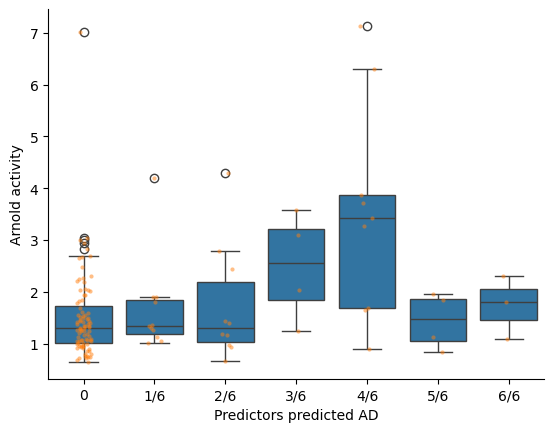

In [294]:
ax = sns.boxplot(x=test_data[test_data['screen'] == 'arnold']['max_value'], y=test_data[test_data['screen'] == 'arnold']['activity'])

sns.stripplot(data=test_data[test_data['screen'] == 'arnold'], x='max_value', y='activity', 
              dodge=True, alpha=0.5, legend=False, ax=ax, size=3)

plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
plt.xlabel("Predictors predicted AD")
plt.ylabel("Arnold activity")
sns.despine()

In [295]:
# We want this to be PRC curve
def has_AD(activity_ls, threshold=0.5):
    counter = 0
    for i in activity_ls: 
        if i >= threshold: 
            counter += 1
        else: 
            counter = 0
        if counter >= 10: 
            return True
    
    return False

In [500]:
test_data['paddle_AD'] = [isinstance(a, str) or (ast.literal_eval(ls)[0] > 3.8) for a, ls in zip(test_data['paddle_intervals'], test_data['paddle_preds'])]


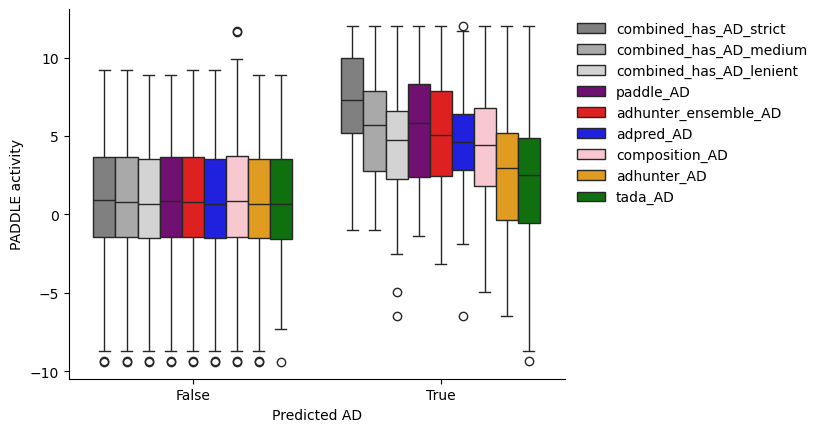

In [501]:
test_data['adhunter_ensemble_AD'] = [isinstance(a, str) for a in test_data['adhunter_ensemble_intervals']]
test_data['adhunter_ensemble_AD'] = [isinstance(a, str) for a in test_data['adhunter_ensemble_intervals']]
test_data['tada_AD'] = [isinstance(a, str) for a in test_data['tada_intervals']]
test_data['adpred_AD'] = [isinstance(a, str) for a in test_data['adpred_intervals']]
test_data['composition_AD'] = [isinstance(a, str) for a in test_data['composition_intervals']]
test_data['adhunter_AD'] = [isinstance(a, str) for a in test_data['adhunter_intervals']]


# 5 or more predictors saying yes
test_data['combined_has_AD_strict'] = [has_AD(ast.literal_eval(ls), threshold=0.8) for ls in test_data['combined_preds']]

# 4 or more predictors saying yes
test_data['combined_has_AD_medium'] = [has_AD(ast.literal_eval(ls), threshold=0.6) for ls in test_data['combined_preds']]

# 3 or more predictors saying yes
test_data['combined_has_AD_lenient'] = [has_AD(ast.literal_eval(ls), threshold=0.4) for ls in test_data['combined_preds']]

delrosso = test_data[test_data['screen'] == 'delrosso']
plot_df = delrosso.melt(
    value_vars=['combined_has_AD_strict', 'combined_has_AD_medium', 'combined_has_AD_lenient', 'paddle_AD', 'adhunter_ensemble_AD','adpred_AD', 'composition_AD', 'adhunter_AD', 'tada_AD',],
    id_vars=['activity'],
    var_name='model',
    value_name='score',
)

sns.boxplot(data=plot_df, x='score', y='activity', hue='model', 
            palette=['grey', 'darkgrey', 'lightgrey', 'purple', 'red', 'blue', 'pink', 'orange', 'green'])
# plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
# plt.xlabel("Predictors predicted AD")
# plt.ylabel("Del Rosso activity")

plt.legend(frameon=False, bbox_to_anchor=(1,1))
plt.xlabel("Predicted AD")
plt.ylabel("PADDLE activity")
sns.despine()


In [148]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report


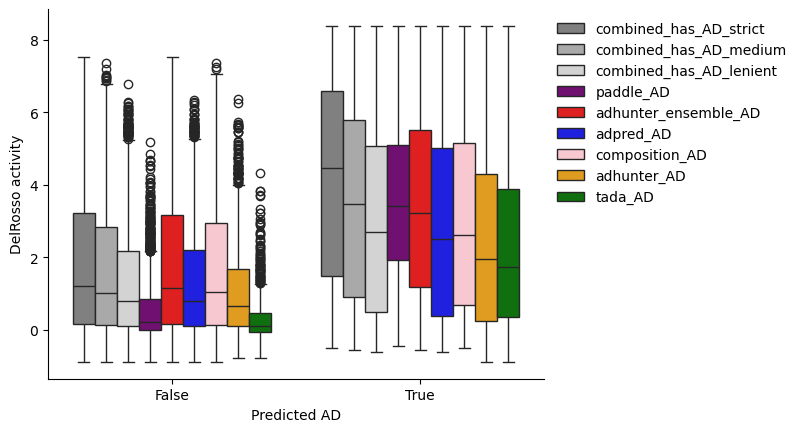

In [146]:
sanborn = test_data[test_data['screen'] == 'sanborn']
plot_df = sanborn.melt(
    value_vars=['combined_has_AD_strict', 'combined_has_AD_medium', 'combined_has_AD_lenient', 'paddle_AD', 'adhunter_ensemble_AD','adpred_AD', 'composition_AD', 'adhunter_AD', 'tada_AD',],
    id_vars=['activity'],
    var_name='model',
    value_name='score',
)

sns.boxplot(data=plot_df, x='score', y='activity', hue='model', 
            palette=['grey', 'darkgrey', 'lightgrey', 'purple', 'red', 'blue', 'pink', 'orange', 'green'])
# plt.xticks([0, 1, 2, 3, 4, 5, 6], ["0", "1/6", "2/6", "3/6", "4/6", "5/6", '6/6'])
# plt.xlabel("Predictors predicted AD")
# plt.ylabel("Del Rosso activity")

plt.legend(frameon=False, bbox_to_anchor=(1,1))
plt.xlabel("Predicted AD")
plt.ylabel("DelRosso activity")
sns.despine()


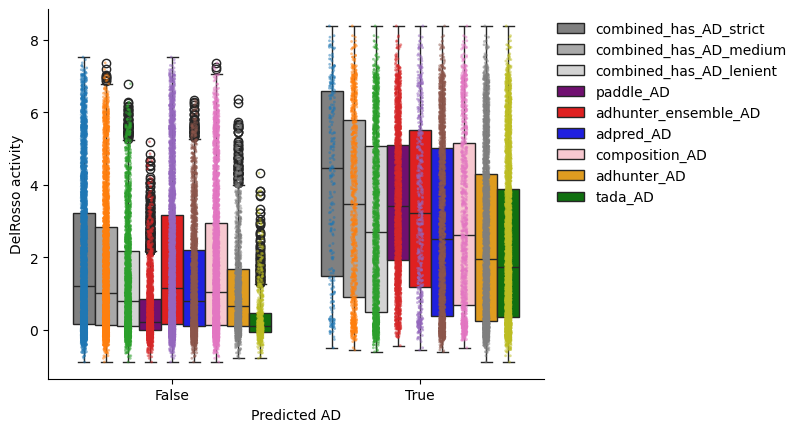

In [165]:
sanborn = test_data[test_data['screen'] == 'sanborn']
plot_df = sanborn.melt(
    value_vars=['combined_has_AD_strict', 'combined_has_AD_medium', 'combined_has_AD_lenient', 'paddle_AD', 'adhunter_ensemble_AD','adpred_AD', 'composition_AD', 'adhunter_AD', 'tada_AD',],
    id_vars=['activity'],
    var_name='model',
    value_name='score',
)
palette=['grey', 'darkgrey', 'lightgrey', 'purple', 'red', 'blue', 'pink', 'orange', 'green']
ax = sns.boxplot(data=plot_df, x='score', y='activity', hue='model', 
            palette=palette)

sns.stripplot(data=plot_df, x='score', y='activity', hue='model',
              dodge=True, alpha=0.5, legend=False, ax=ax, size=2)
   
plt.legend(frameon=False, bbox_to_anchor=(1,1))
plt.xlabel("Predicted AD")
plt.ylabel("DelRosso activity")
sns.despine()


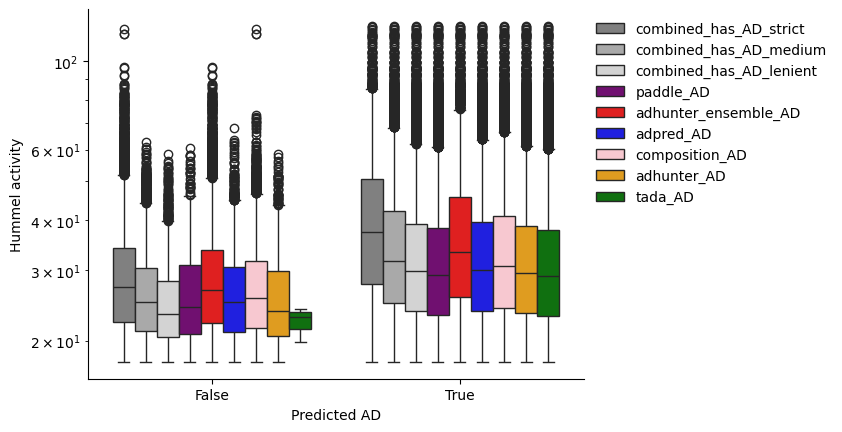

In [220]:
hummel = test_data[test_data['screen'] == 'hummel']
plot_df = hummel.melt(
    value_vars=['combined_has_AD_strict', 'combined_has_AD_medium', 'combined_has_AD_lenient', 'paddle_AD', 'adhunter_ensemble_AD','adpred_AD', 'composition_AD', 'adhunter_AD', 'tada_AD',],
    id_vars=['activity'],
    var_name='model',
    value_name='score',
)
palette=['grey', 'darkgrey', 'lightgrey', 'purple', 'red', 'blue', 'pink', 'orange', 'green']
ax = sns.boxplot(data=plot_df, x='score', y='activity', hue='model', 
            palette=palette)
plt.yscale('log')
# sns.stripplot(data=plot_df, x='score', y='activity', hue='model',
#               dodge=True, alpha=0.5, legend=False, ax=ax, size=2)
   
plt.legend(frameon=False, bbox_to_anchor=(1,1))
plt.xlabel("Predicted AD")
plt.ylabel("Hummel activity")
sns.despine()


In [217]:
2**13

8192

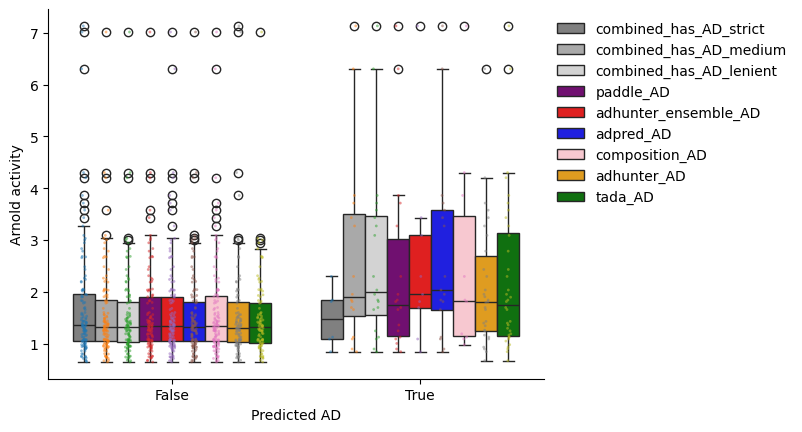

In [164]:
arnold = test_data[test_data['screen'] == 'arnold']
plot_df = arnold.melt(
    value_vars=['combined_has_AD_strict', 'combined_has_AD_medium', 'combined_has_AD_lenient', 'paddle_AD', 'adhunter_ensemble_AD','adpred_AD', 'composition_AD', 'adhunter_AD', 'tada_AD',],
    id_vars=['activity'],
    var_name='model',
    value_name='score',
)

ax = sns.boxplot(data=plot_df, x='score', y='activity', hue='model', 
            palette=palette)
sns.stripplot(data=plot_df, x='score', y='activity', hue='model',
              dodge=True, alpha=0.5, legend=False, ax=ax, size=2)

plt.legend(frameon=False, bbox_to_anchor=(1,1))
plt.xlabel("Predicted AD")
plt.ylabel("Arnold activity")
sns.despine()


In [297]:
def calculate_precision_recall(df, true_threshold, pred_column): 
    y_true = df['activity'] > true_threshold
    y_pred = df[pred_column]

    precision = precision_score(y_true, y_pred) # How many positives were actually positive?
    recall = recall_score(y_true, y_pred) # How many positives did we find (out of all positives)?
    f1 = f1_score(y_true, y_pred) 
    return precision, recall, f1

In [198]:
threshold = 3.5
paddle_p, paddle_r, paddle_f1 = calculate_precision_recall(sanborn, threshold, 'paddle_AD')
tada_p, tada_r, tada_f1 = calculate_precision_recall(sanborn, threshold, 'tada_AD')
adhunter_p, adhunter_r, adhunter_f1 = calculate_precision_recall(sanborn, threshold, 'adhunter_AD')
adpred_p, adpred_r, adpred_f1 = calculate_precision_recall(sanborn, threshold, 'adpred_AD')
adhunter_ensemble_p, adhunter_ensemble_r, adhunter_ensemble_f1 = calculate_precision_recall(sanborn, threshold, 'adhunter_ensemble_AD')
comp_p, comp_r, comp_f1 = calculate_precision_recall(sanborn, threshold, 'composition_AD')

consensus_strict_p, consensus_strict_r, consensus_strict_f1 = calculate_precision_recall(sanborn, threshold, 'combined_has_AD_strict')
consensus_medium_p, consensus_medium_r, consensus_medium_f1 = calculate_precision_recall(sanborn, threshold, 'combined_has_AD_medium')
consensus_lenient_p, consensus_lenient_r, consensus_lenient_f1 = calculate_precision_recall(sanborn, threshold, 'combined_has_AD_lenient')



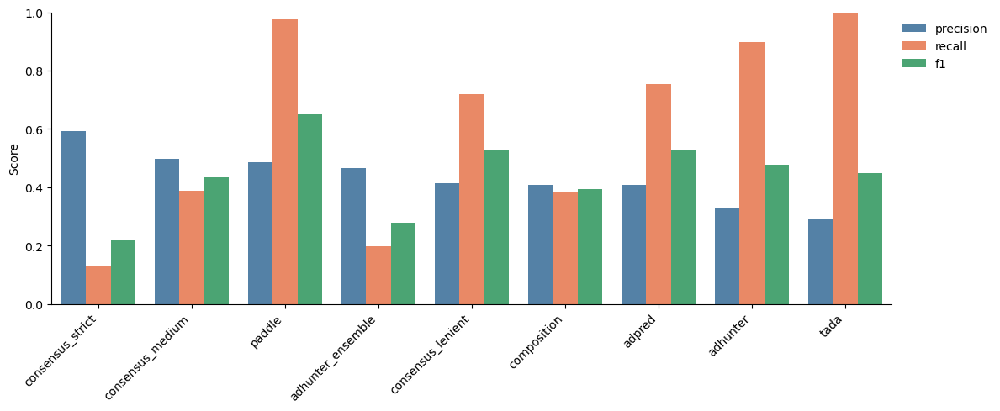

In [199]:
plot_df = pd.DataFrame({
    'model':     ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 'consensus_strict', 'consensus_medium', 'consensus_lenient'],
    'precision': [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, consensus_strict_p, consensus_medium_p, consensus_lenient_p],
    'recall':    [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, consensus_strict_r, consensus_medium_r, consensus_lenient_r],
    'f1':        [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1],
})

# Sort by precision first, then recall
plot_df = plot_df.sort_values(['precision', 'recall'], ascending=False)

# Melt to long format
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric', 
            palette=['steelblue', 'coral', 'mediumseagreen'],
            order=plot_df['model'].unique())  # preserve sort order

plt.xticks(rotation=45, ha='right')
plt.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
sns.despine()
plt.tight_layout()

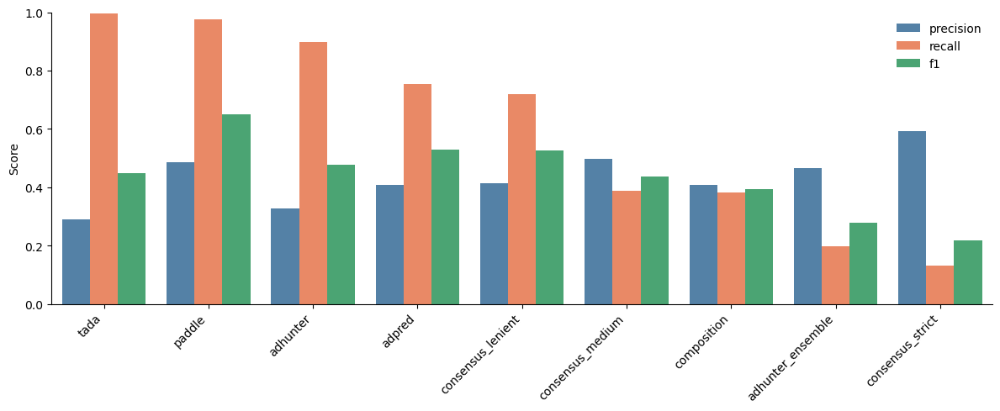

In [201]:
plot_df = pd.DataFrame({
    'model':     ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 'consensus_strict', 'consensus_medium', 'consensus_lenient'],
    'precision': [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, consensus_strict_p, consensus_medium_p, consensus_lenient_p],
    'recall':    [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, consensus_strict_r, consensus_medium_r, consensus_lenient_r],
    'f1':        [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1],
})

# Sort by precision first, then recall
plot_df = plot_df.sort_values(['recall', 'precision'], ascending=False)

# Melt to long format
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric', 
            palette=['steelblue', 'coral', 'mediumseagreen'],
            order=plot_df['model'].unique())  # preserve sort order

plt.xticks(rotation=45, ha='right')
plt.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
sns.despine()
plt.tight_layout()

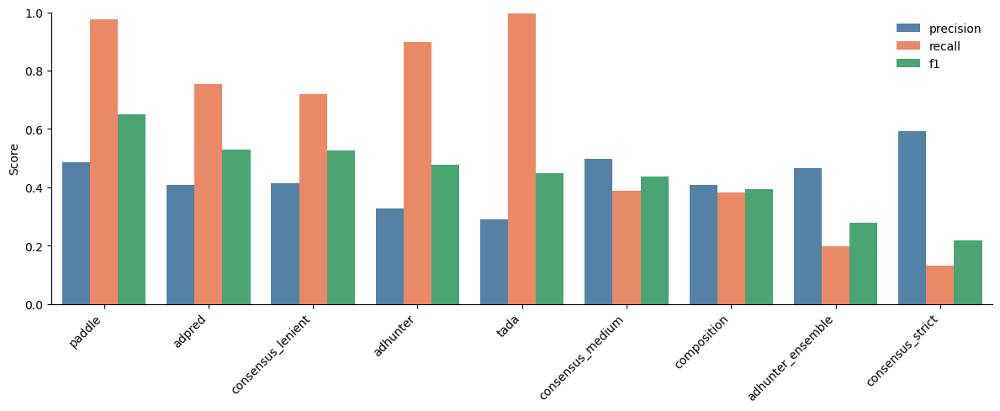

In [202]:
plot_df = pd.DataFrame({
    'model':     ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 'consensus_strict', 'consensus_medium', 'consensus_lenient'],
    'precision': [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, consensus_strict_p, consensus_medium_p, consensus_lenient_p],
    'recall':    [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, consensus_strict_r, consensus_medium_r, consensus_lenient_r],
    'f1':        [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1],
})

# Sort by precision first, then recall
plot_df = plot_df.sort_values(['f1'], ascending=False)

# Melt to long format
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric', 
            palette=['steelblue', 'coral', 'mediumseagreen'],
            order=plot_df['model'].unique())  # preserve sort order

plt.xticks(rotation=45, ha='right')
plt.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
sns.despine()
plt.tight_layout()

In [498]:
test_data_parrot['no_sanjana_has_AD_strict'] = [has_AD([float(n) for n in ls], 0.8) for ls in test_data_parrot['parrot_preds_no_sanjana']] # 4/5
test_data_parrot['no_sanjana_has_AD_medium'] = [has_AD([float(n) for n in ls], 0.6) for ls in test_data_parrot['parrot_preds_no_sanjana']] # 3/5
test_data_parrot['no_sanjana_has_AD_lenient'] = [has_AD([float(n) for n in ls], 0.4) for ls in test_data_parrot['parrot_preds_no_sanjana']] # 2/5

test_data_parrot['all_six_has_AD_strict'] = [has_AD([float(n) for n in ls], 0.8) for ls in test_data_parrot['parrot_preds_all_six']] 
test_data_parrot['all_six_has_AD_medium'] = [has_AD([float(n) for n in ls], 0.6) for ls in test_data_parrot['parrot_preds_all_six']]
test_data_parrot['all_six_has_AD_lenient'] = [has_AD([float(n) for n in ls], 0.4) for ls in test_data_parrot['parrot_preds_all_six']]

In [571]:
# Need to look more deeply into this 
threshold = 3
paddle_p, paddle_r, paddle_f1 = calculate_precision_recall(delrosso, threshold, 'paddle_AD')
tada_p, tada_r, tada_f1 = calculate_precision_recall(delrosso, threshold, 'tada_AD')
adhunter_p, adhunter_r, adhunter_f1 = calculate_precision_recall(delrosso, threshold, 'adhunter_AD')
adpred_p, adpred_r, adpred_f1 = calculate_precision_recall(delrosso, threshold, 'adpred_AD')
adhunter_ensemble_p, adhunter_ensemble_r, adhunter_ensemble_f1 = calculate_precision_recall(delrosso, threshold, 'adhunter_ensemble_AD')
comp_p, comp_r, comp_f1 = calculate_precision_recall(delrosso, threshold, 'composition_AD')

consensus_strict_p, consensus_strict_r, consensus_strict_f1 = calculate_precision_recall(delrosso, threshold, 'combined_has_AD_strict')
consensus_medium_p, consensus_medium_r, consensus_medium_f1 = calculate_precision_recall(delrosso, threshold, 'combined_has_AD_medium')
consensus_lenient_p, consensus_lenient_r, consensus_lenient_f1 = calculate_precision_recall(delrosso, threshold, 'combined_has_AD_lenient')

# With parrot predictions
no_sanjana_strict_p, no_sanjana_strict_r, no_sanjana_strict_f1 = calculate_precision_recall(test_data_parrot[test_data_parrot['screen'] == 'delrosso'], threshold, 'no_sanjana_has_AD_strict')
no_sanjana_medium_p, no_sanjana_medium_r, no_sanjana_medium_f1 = calculate_precision_recall(test_data_parrot[test_data_parrot['screen'] == 'delrosso'], threshold, 'no_sanjana_has_AD_medium')
no_sanjana_lenient_p, no_sanjana_lenient_r, no_sanjana_lenient_f1 = calculate_precision_recall(test_data_parrot[test_data_parrot['screen'] == 'delrosso'], threshold, 'no_sanjana_has_AD_lenient')

all_six_strict_p, all_six_strict_r, all_six_strict_f1 = calculate_precision_recall(test_data_parrot[test_data_parrot['screen'] == 'delrosso'], threshold, 'all_six_has_AD_strict')
all_six_medium_p, all_six_medium_r, all_six_medium_f1 = calculate_precision_recall(test_data_parrot[test_data_parrot['screen'] == 'delrosso'], threshold, 'all_six_has_AD_medium')
all_six_lenient_p, all_six_lenient_r, all_six_lenient_f1 = calculate_precision_recall(test_data_parrot[test_data_parrot['screen'] == 'delrosso'], threshold, 'all_six_has_AD_lenient')


In [513]:
merged_delrosso = test_data_parrot[test_data_parrot['screen'] == 'delrosso'].merge(delrosso, on=['protein sequence', 'activity', 'screen', 'id'])

In [523]:
y = [float(a) for ls in list(merged_delrosso['parrot_preds_all_six'].values) for a in ls]
x = [a for ls in list(merged_delrosso['combined_preds'].values) for a in ast.literal_eval(ls)]

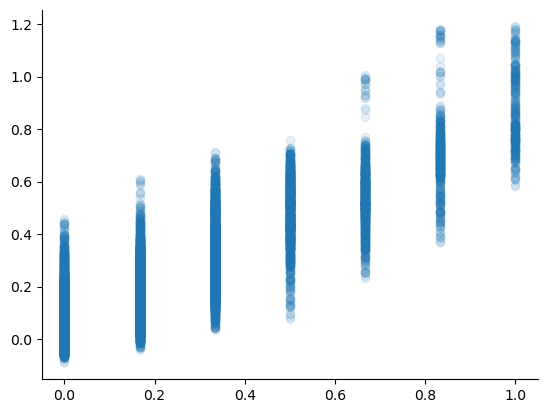

In [530]:
y = [float(a) for ls in list(merged_delrosso['parrot_preds_all_six'].values) for a in ls]
x = [a for ls in list(merged_delrosso['combined_preds'].values) for a in ast.literal_eval(ls)]
plt.scatter(x, y, alpha=0.1)

sns.despine()

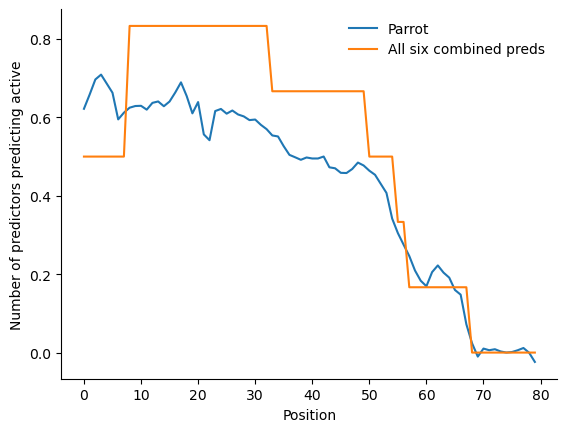

In [ ]:
i= 22
plt.plot([float(a) for a in merged_delrosso['parrot_preds_all_six'].loc[i]],
            label='Parrot')
plt.plot([float(a) for a in ast.literal_eval(merged_delrosso['combined_preds'].loc[i])],
            label='All six combined preds')
plt.xlabel('Position')
plt.ylabel("Number of predictors predicting active")
plt.legend(frameon=False)
sns.despine()

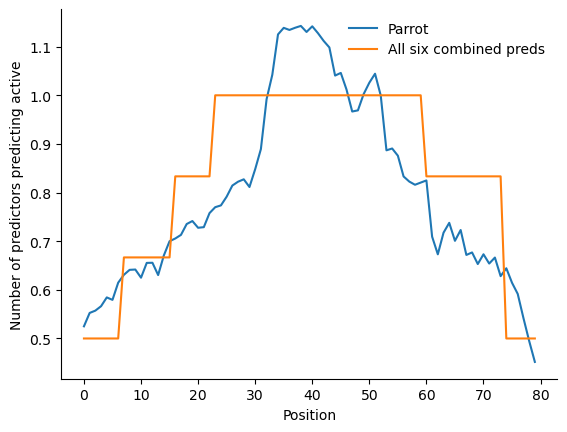

In [ ]:
# This is an example of an issue with my thresholding 
i= 357
plt.plot([float(a) for a in merged_delrosso['parrot_preds_all_six'].loc[i]],
            label='Parrot')
plt.plot([float(a) for a in ast.literal_eval(merged_delrosso['combined_preds'].loc[i])],
            label='All six combined preds')
plt.xlabel('Position')
plt.ylabel("Number of predictors predicting active")
plt.legend(frameon=False)
sns.despine()

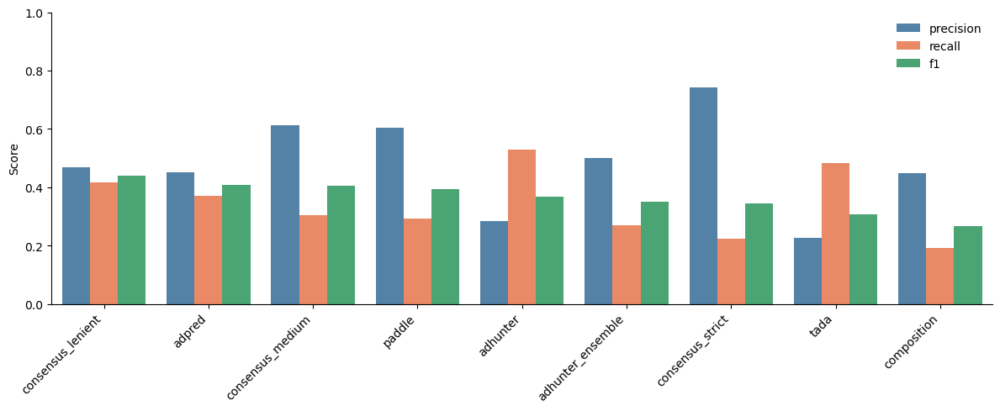

In [567]:
plot_df = pd.DataFrame({
    'model':     ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 'consensus_strict', 'consensus_medium', 'consensus_lenient'],
    'precision': [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, consensus_strict_p, consensus_medium_p, consensus_lenient_p],
    'recall':    [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, consensus_strict_r, consensus_medium_r, consensus_lenient_r],
    'f1':        [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1],
})

# Sort by precision first, then recall
plot_df = plot_df.sort_values(['f1'], ascending=False)

# Melt to long format
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric', 
            palette=['steelblue', 'coral', 'mediumseagreen'],
            order=plot_df['model'].unique())  # preserve sort order

plt.xticks(rotation=45, ha='right')
plt.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
sns.despine()
plt.tight_layout()

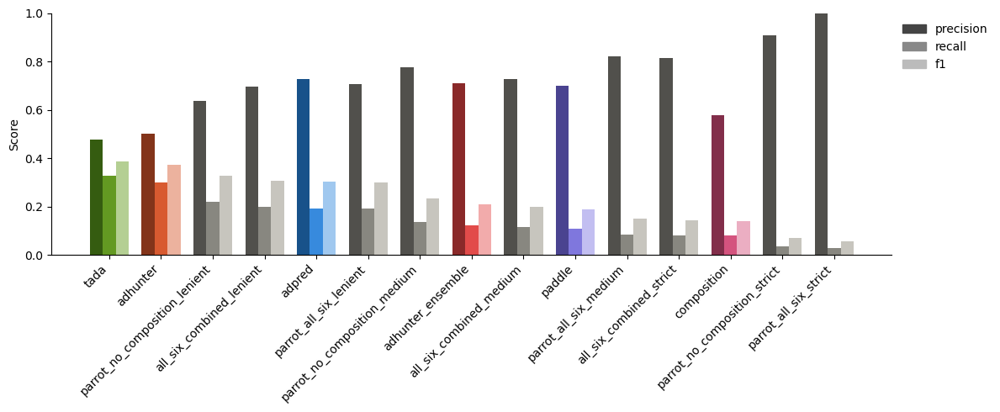

In [572]:
models = ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 
            'all_six_combined_strict', 'all_six_combined_medium', 'all_six_combined_lenient', 
            'parrot_no_composition_strict', 'parrot_no_composition_medium', 'parrot_no_composition_lenient',
            'parrot_all_six_strict', 'parrot_all_six_medium', 'parrot_all_six_lenient']

precisions = [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, 
                consensus_strict_p, consensus_medium_p, consensus_lenient_p,
                no_sanjana_strict_p, no_sanjana_medium_p, no_sanjana_lenient_p,
                all_six_strict_p, all_six_medium_p, all_six_lenient_p]
recalls = [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, 
            consensus_strict_r, consensus_medium_r, consensus_lenient_r,
            no_sanjana_strict_r, no_sanjana_medium_r, no_sanjana_lenient_r,
            all_six_strict_r, all_six_medium_r, all_six_lenient_r]
f1s  = [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, 
        consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1,
        no_sanjana_strict_f1, no_sanjana_medium_f1, no_sanjana_lenient_f1, 
        all_six_strict_f1, all_six_medium_f1, all_six_lenient_f1]

# sort by precision
# per-model colors: [light, mid, dark] = [f1, recall, precision]
ramps = [
    ['#C2BEF1', '#7F77DD', '#4A4390'],  # paddle
    ['#B4CF93', '#639922', '#355C10'], # tada
    ['#ECB29E', '#D85A30', '#83341A'],  # adhunter
    # ['#B4CF93', '#639922', '#355C10'], # adhunter
    ['#A0C8EF', '#378ADD', '#18528A'],  # adpred
    ['#F2ABAB', '#E24B4A', '#8A2929'],  # adhunter ensemble

    ['#EBAEC2', '#D4537E', '#822E4A'],  # composition

    ['#C7C5BE', '#888780', '#51504C'],  # gray
    ['#C7C5BE', '#888780', '#51504C'],  # gray
    ['#C7C5BE', '#888780', '#51504C'],  # gray
    
    ['#C7C5BE', '#888780', '#51504C'],  # gray
    ['#C7C5BE', '#888780', '#51504C'],  # gray
    ['#C7C5BE', '#888780', '#51504C'],  # gray

    ['#C7C5BE', '#888780', '#51504C'],  # gray
    ['#C7C5BE', '#888780', '#51504C'],  # gray
    ['#C7C5BE', '#888780', '#51504C'],  # gray
]

order = sorted(range(len(models)), key=lambda i: f1s[i], reverse=True)
models     = [models[i] for i in order]
precisions = [precisions[i] for i in order]
recalls    = [recalls[i] for i in order]
f1s        = [f1s[i] for i in order]
ramps = [ramps[i] for i in order]


n = len(models)
x = np.arange(n)
w = 0.25

fig, ax = plt.subplots(figsize=(12, 5))

for i, (p, r, f, ramp) in enumerate(zip(precisions, recalls, f1s, ramps)):
    ax.bar(x[i] - w,   p, w, color=ramp[2])  # dark  = precision
    ax.bar(x[i],       r, w, color=ramp[1])  # mid   = recall
    ax.bar(x[i] + w,   f, w, color=ramp[0])  # light = f1

ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

from matplotlib.patches import Patch
legend = [Patch(color='#444', label='precision'),
          Patch(color='#888', label='recall'),
          Patch(color='#bbb', label='f1')]
ax.legend(handles=legend, frameon=False, bbox_to_anchor=(1, 1))

sns.despine()
plt.tight_layout()
plt.show()

In [232]:
# Need to look more deeply into this 
threshold=40
paddle_p, paddle_r, paddle_f1 = calculate_precision_recall(hummel, threshold, 'paddle_AD')
tada_p, tada_r, tada_f1 = calculate_precision_recall(hummel, threshold, 'tada_AD')
adhunter_p, adhunter_r, adhunter_f1 = calculate_precision_recall(hummel, threshold, 'adhunter_AD')
adpred_p, adpred_r, adpred_f1 = calculate_precision_recall(hummel, threshold, 'adpred_AD')
adhunter_ensemble_p, adhunter_ensemble_r, adhunter_ensemble_f1 = calculate_precision_recall(hummel, threshold, 'adhunter_ensemble_AD')
comp_p, comp_r, comp_f1 = calculate_precision_recall(hummel, threshold, 'composition_AD')

consensus_strict_p, consensus_strict_r, consensus_strict_f1 = calculate_precision_recall(hummel, threshold, 'combined_has_AD_strict')
consensus_medium_p, consensus_medium_r, consensus_medium_f1 = calculate_precision_recall(hummel, threshold, 'combined_has_AD_medium')
consensus_lenient_p, consensus_lenient_r, consensus_lenient_f1 = calculate_precision_recall(hummel, threshold, 'combined_has_AD_lenient')



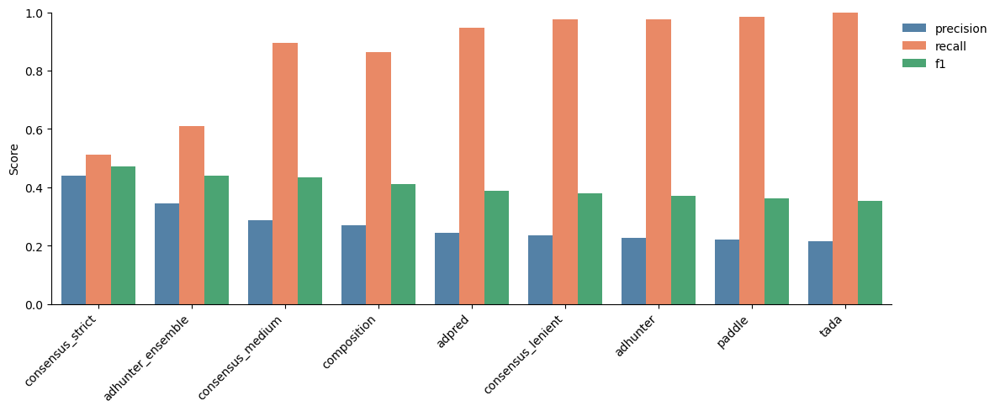

In [233]:
plot_df = pd.DataFrame({
    'model':     ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 'consensus_strict', 'consensus_medium', 'consensus_lenient'],
    'precision': [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, consensus_strict_p, consensus_medium_p, consensus_lenient_p],
    'recall':    [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, consensus_strict_r, consensus_medium_r, consensus_lenient_r],
    'f1':        [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1],
})

# Sort by precision first, then recall
plot_df = plot_df.sort_values(['precision'], ascending=False)

# Melt to long format
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric', 
            palette=['steelblue', 'coral', 'mediumseagreen'],
            order=plot_df['model'].unique())  # preserve sort order

plt.xticks(rotation=45, ha='right')
plt.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
sns.despine()
plt.tight_layout()

In [422]:
def calculate_precision_recall_all(column): 
    y_true = pd.concat([sanborn['activity'] > 3, hummel['activity'] > 30, delrosso['activity'] > 3])
    y_pred = pd.concat([sanborn[column], hummel[column], delrosso[column]])
    precision = precision_score(y_true, y_pred) # How many positives were actually positive?
    recall = recall_score(y_true, y_pred) # How many positives did we find (out of all positives)?
    f1 = f1_score(y_true, y_pred) 
    return precision, recall, f1


In [423]:
paddle_p, paddle_r, paddle_f1 = calculate_precision_recall_all('paddle_AD')
tada_p, tada_r, tada_f1 = calculate_precision_recall_all('tada_AD')
adhunter_p, adhunter_r, adhunter_f1 = calculate_precision_recall_all('adhunter_AD')
adpred_p, adpred_r, adpred_f1 = calculate_precision_recall_all('adpred_AD')
adhunter_ensemble_p, adhunter_ensemble_r, adhunter_ensemble_f1 = calculate_precision_recall_all('adhunter_ensemble_AD')
comp_p, comp_r, comp_f1 = calculate_precision_recall_all('composition_AD')

consensus_strict_p, consensus_strict_r, consensus_strict_f1 = calculate_precision_recall_all('combined_has_AD_strict')
consensus_medium_p, consensus_medium_r, consensus_medium_f1 = calculate_precision_recall_all('combined_has_AD_medium')
consensus_lenient_p, consensus_lenient_r, consensus_lenient_f1 = calculate_precision_recall_all('combined_has_AD_lenient')

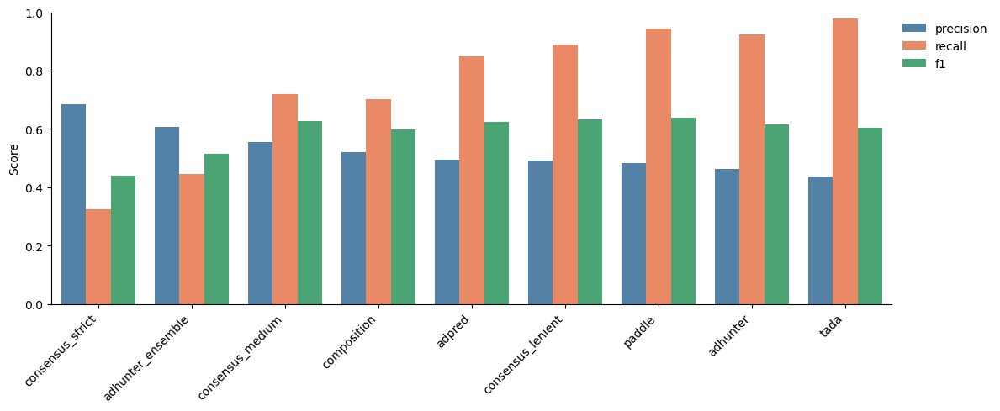

In [424]:
plot_df = pd.DataFrame({
    'model':     ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 'consensus_strict', 'consensus_medium', 'consensus_lenient'],
    'precision': [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, consensus_strict_p, consensus_medium_p, consensus_lenient_p],
    'recall':    [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, consensus_strict_r, consensus_medium_r, consensus_lenient_r],
    'f1':        [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1],
})

# Sort by precision first, then recall
plot_df = plot_df.sort_values(['precision'], ascending=False)

# Melt to long format
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric', 
            palette=['steelblue', 'coral', 'mediumseagreen'],
            order=plot_df['model'].unique())  # preserve sort order

plt.xticks(rotation=45, ha='right')
plt.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
sns.despine()
plt.tight_layout()

In [101]:
# We want this to be PRC curve
def has_AD(activity_ls, threshold=0.5):
    counter = 0
    for i in activity_ls: 
        if i >= threshold: 
            counter += 1
        else: 
            counter = 0
        if counter >= 20: 
            return True
    
    return False

In [157]:
def has_AD_ls(df, threshold): 
    return [has_AD(ast.literal_eval(ls), threshold) for ls in df['combined_preds']]

In [192]:
sanborn_subset['has_AD'] = [has_AD(ast.literal_eval(ls), 0.8) for ls in sanborn_subset['combined_preds']]

/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_13855/2921293951.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sanborn_subset['has_AD'] = [has_AD(ast.literal_eval(ls), 0.8) for ls in sanborn_subset['combined_preds']]


In [ ]:
sanborn_subset['active'] = sanborn_subset['activity'] > 7

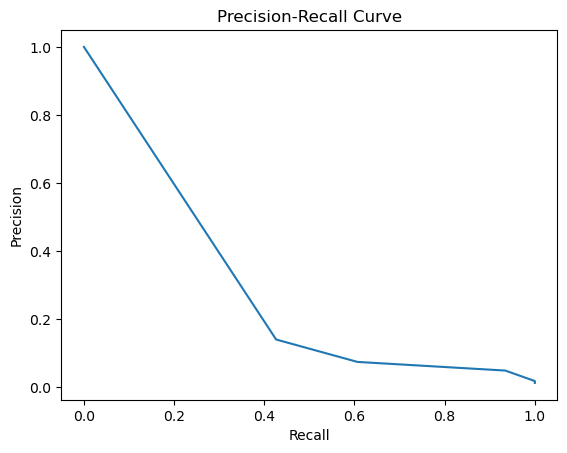

In [187]:
# Your scores and true labels
scores = sanborn_subset
true_labels = sanborn_subset['active']

# Define thresholds to sweep over
thresholds = np.linspace(0, 1.4, 100)

# Compute precision and recall at each threshold manually
precisions = []
recalls = []

for t in thresholds:
    preds = np.array(has_AD_ls(scores, t)).astype(int)
    
    tp = np.sum((preds == 1) & (true_labels == 1))
    fp = np.sum((preds == 1) & (true_labels == 0))
    fn = np.sum((preds == 0) & (true_labels == 1))
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 1.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    precisions.append(precision)
    recalls.append(recall)

# Plot
plt.plot(recalls, precisions)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.show()

In [194]:
sanborn_subset['active'] = sanborn_subset['activity'] > 7
sanborn_subset[['active', 'has_AD']].value_counts()

/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_13855/698730937.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sanborn_subset['active'] = sanborn_subset['activity'] > 7


active  has_AD
False   False     4454
        True       159
True    False       35
        True        26
Name: count, dtype: int64

Text(0.5, 1.0, '8.39 True')

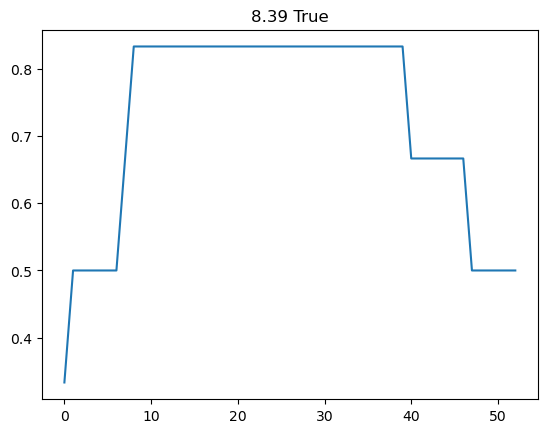

In [184]:
i = 1345 # We get this one! 
plt.plot(ast.literal_eval(sanborn_subset.loc[i, 'combined_preds']))
plt.title(str(sanborn_subset.loc[i, 'activity']) + " " + str(sanborn_subset.loc[i, 'has_AD']))

In [152]:
sanborn_subset[['has_AD', 'active']].value_counts()

has_AD  active
False   False     2390
True    False     1217
        True       792
False   True       275
Name: count, dtype: int64

In [186]:
# These are vibes based thresholds
sanborn_subset['active'] = sanborn_subset['activity'] > 7
hummel_subset['active'] = hummel_subset['activity'] > 50
arnold_subset['active'] = arnold_subset['activity'] > 2.5
delrosso_subset['active'] = delrosso_subset['activity'] > 2

/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_13855/2406036833.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sanborn_subset['active'] = sanborn_subset['activity'] > 7
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_13855/2406036833.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hummel_subset['active'] = hummel_subset['activity'] > 50
/var/folders/34/1pw3__x51kdfyh3vk72f5vc80000gn/T/ipykernel_13855/2406036833.py:4: SettingWithCopyWarning: 
A value is trying to be set on a c

<Axes: ylabel='activity'>

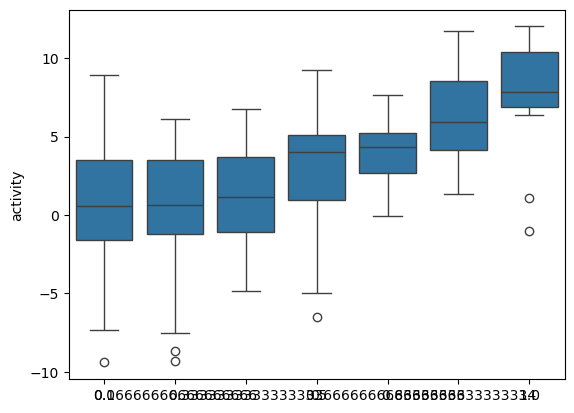

In [143]:
sns.boxplot(x = [np.max(ast.literal_eval(ls)) for ls in delrosso_subset['combined_preds']], y = delrosso_subset['activity'])

<Axes: ylabel='activity'>

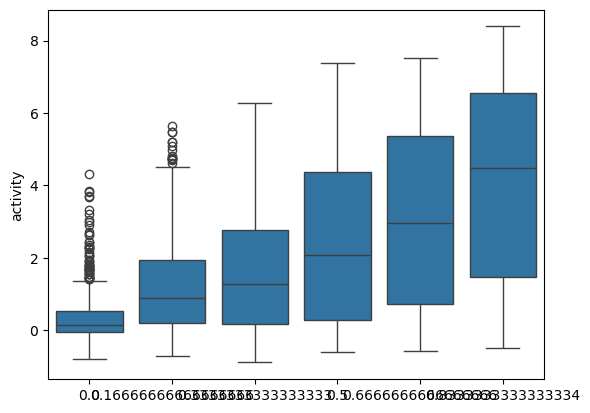

In [145]:
sns.boxplot(x = [np.max(ast.literal_eval(ls)) for ls in sanborn_subset['combined_preds']], y = sanborn_subset['activity'])

<Axes: ylabel='activity'>

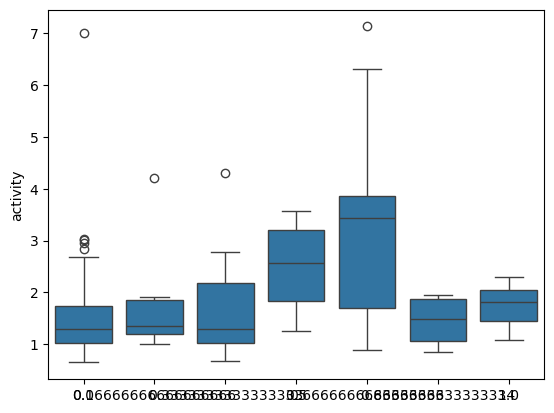

In [146]:
sns.boxplot(x = [np.max(ast.literal_eval(ls)) for ls in arnold_subset['combined_preds']], y = arnold_subset['activity'])

In [ ]:
sns.boxplot(x = [np.max(ast.literal_eval(ls)) for ls in arnold_subset['combined_preds']], y = arnold_subset['activity'])

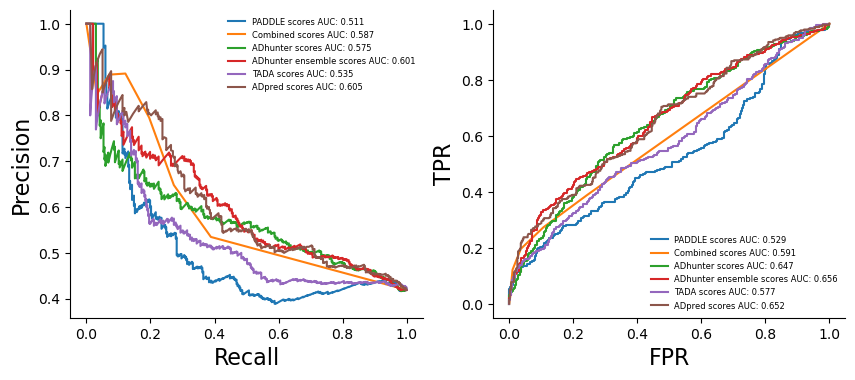

In [140]:
# Code to plot the PRC curves and the ROC curves

fig, axs = plt.subplots(1,2,figsize=(10,4))

# Get true labels (based on threshold of 2000)
experimental_labels = delrosso_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in delrosso_subset['paddle_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)

# Plotting precision recall curves
axs[0].plot(recall_b, precision_b, label=f"PADDLE scores AUC: {biophysics_auc_pr:.3}")
# Plotting ROC curves
axs[1].plot(fpr_b, tpr_b, label=f"PADDLE scores AUC: {biophysics_auc_roc:.3}")


# Get true labels (based on threshold of 2000)
experimental_labels = delrosso_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in delrosso_subset['combined_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"Combined scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"Combined scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in delrosso_subset['adhunter_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in delrosso_subset['adhunter_ensemble_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)


# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in delrosso_subset['tada_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"TADA scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"TADA scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in delrosso_subset['adpred_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADpred scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADpred scores AUC: {biophysics_auc_roc:.3}")


axs[0].legend(fontsize="6", frameon=False)
axs[0].set_xlabel("Recall", fontsize=16)
axs[0].set_ylabel("Precision", fontsize=16)



axs[1].legend(fontsize="6", frameon=False)
axs[1].set_xlabel("FPR", fontsize=16)
axs[1].set_ylabel("TPR", fontsize=16)

sns.despine()

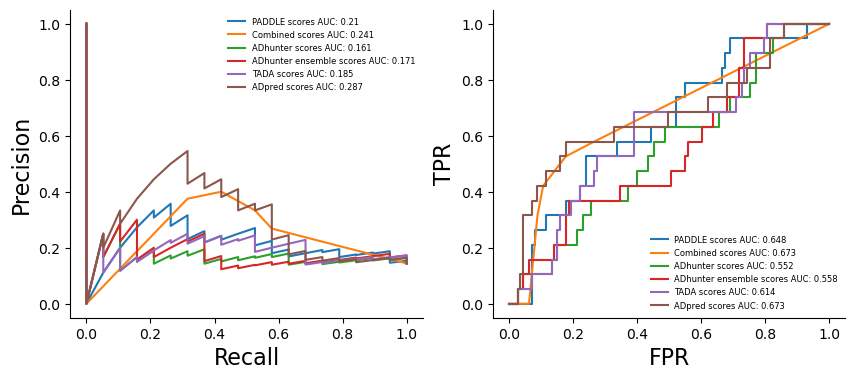

In [135]:
# Code to plot the PRC curves and the ROC curves

fig, axs = plt.subplots(1,2,figsize=(10,4))

# Get true labels (based on threshold of 2000)
experimental_labels = arnold_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in arnold_subset['paddle_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)

# Plotting precision recall curves
axs[0].plot(recall_b, precision_b, label=f"PADDLE scores AUC: {biophysics_auc_pr:.3}")
# Plotting ROC curves
axs[1].plot(fpr_b, tpr_b, label=f"PADDLE scores AUC: {biophysics_auc_roc:.3}")


# Get true labels (based on threshold of 2000)
experimental_labels = arnold_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in arnold_subset['combined_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"Combined scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"Combined scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in arnold_subset['adhunter_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in arnold_subset['adhunter_ensemble_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)


# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in arnold_subset['tada_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"TADA scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"TADA scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in arnold_subset['adpred_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADpred scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADpred scores AUC: {biophysics_auc_roc:.3}")


axs[0].legend(fontsize="6", frameon=False)
axs[0].set_xlabel("Recall", fontsize=16)
axs[0].set_ylabel("Precision", fontsize=16)



axs[1].legend(fontsize="6", frameon=False)
axs[1].set_xlabel("FPR", fontsize=16)
axs[1].set_ylabel("TPR", fontsize=16)

sns.despine()

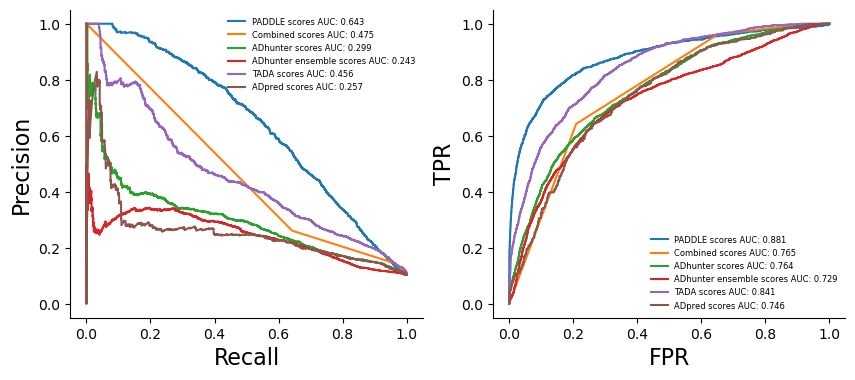

In [132]:
# Code to plot the PRC curves and the ROC curves

fig, axs = plt.subplots(1,2,figsize=(10,4))

# Get true labels (based on threshold of 2000)
experimental_labels = hummel_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in hummel_subset['paddle_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)

# Plotting precision recall curves
axs[0].plot(recall_b, precision_b, label=f"PADDLE scores AUC: {biophysics_auc_pr:.3}")
# Plotting ROC curves
axs[1].plot(fpr_b, tpr_b, label=f"PADDLE scores AUC: {biophysics_auc_roc:.3}")


# Get true labels (based on threshold of 2000)
experimental_labels = hummel_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in hummel_subset['combined_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"Combined scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"Combined scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in hummel_subset['adhunter_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in hummel_subset['adhunter_ensemble_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)


# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in hummel_subset['tada_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"TADA scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"TADA scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in hummel_subset['adpred_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADpred scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADpred scores AUC: {biophysics_auc_roc:.3}")


axs[0].legend(fontsize="6", frameon=False)
axs[0].set_xlabel("Recall", fontsize=16)
axs[0].set_ylabel("Precision", fontsize=16)



axs[1].legend(fontsize="6", frameon=False)
axs[1].set_xlabel("FPR", fontsize=16)
axs[1].set_ylabel("TPR", fontsize=16)

sns.despine()

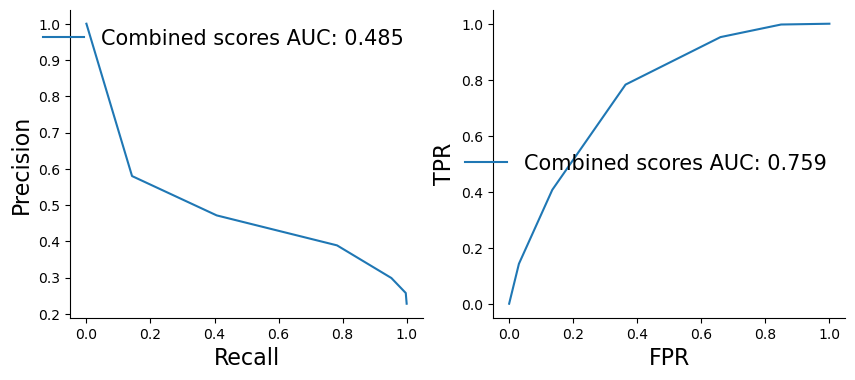

In [112]:
# Code to plot the PRC curves and the ROC curves

fig, axs = plt.subplots(1,2,figsize=(10,4))

# Get true labels (based on threshold of 2000)
experimental_labels = sanborn_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in sanborn_subset['combined_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)

# Plotting precision recall curves

axs[0].plot(recall_b, precision_b, label=f"Combined scores AUC: {biophysics_auc_pr:.3}")


axs[0].legend(fontsize="15", frameon=False)
axs[0].set_xlabel("Recall", fontsize=16)
axs[0].set_ylabel("Precision", fontsize=16)

# Plotting ROC curves
axs[1].plot(fpr_b, tpr_b, label=f"Combined scores AUC: {biophysics_auc_roc:.3}")


axs[1].legend(fontsize="15", frameon=False)
axs[1].set_xlabel("FPR", fontsize=16)
axs[1].set_ylabel("TPR", fontsize=16)

sns.despine()

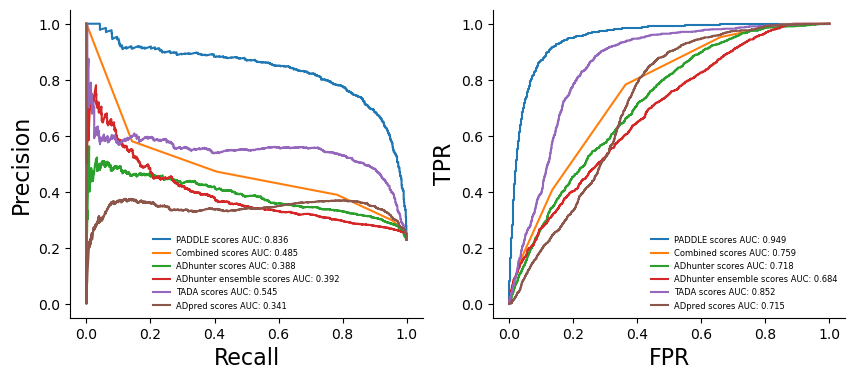

In [120]:
# Code to plot the PRC curves and the ROC curves

fig, axs = plt.subplots(1,2,figsize=(10,4))

# Get true labels (based on threshold of 2000)
experimental_labels = sanborn_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in sanborn_subset['paddle_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)

# Plotting precision recall curves
axs[0].plot(recall_b, precision_b, label=f"PADDLE scores AUC: {biophysics_auc_pr:.3}")
# Plotting ROC curves
axs[1].plot(fpr_b, tpr_b, label=f"PADDLE scores AUC: {biophysics_auc_roc:.3}")


# Get true labels (based on threshold of 2000)
experimental_labels = sanborn_subset["active"]

# Generating biophysical NN curves
biophysical_measures = [np.max(ast.literal_eval(ls)) for ls in sanborn_subset['combined_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"Combined scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"Combined scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in sanborn_subset['adhunter_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in sanborn_subset['adhunter_ensemble_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)

# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)


# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADhunter ensemble scores AUC: {biophysics_auc_roc:.3}")

# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in sanborn_subset['tada_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"TADA scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"TADA scores AUC: {biophysics_auc_roc:.3}")


# Generating biophysical NN curves
biophysical_measures = [np.mean(ast.literal_eval(ls)) for ls in sanborn_subset['adpred_preds']]
precision_b, recall_b, thresholds_b = precision_recall_curve(experimental_labels, biophysical_measures)
fpr_b, tpr_b, thresholds_b = roc_curve(experimental_labels, biophysical_measures)


# Calcualting AUCs for the PRC curves
biophysics_auc_pr = auc(recall_b, precision_b)

# Calcualting AUCs for the ROC curves
biophysics_auc_roc = auc(fpr_b, tpr_b)
axs[0].plot(recall_b, precision_b, label=f"ADpred scores AUC: {biophysics_auc_pr:.3}")
axs[1].plot(fpr_b, tpr_b, label=f"ADpred scores AUC: {biophysics_auc_roc:.3}")


axs[0].legend(fontsize="6", frameon=False)
axs[0].set_xlabel("Recall", fontsize=16)
axs[0].set_ylabel("Precision", fontsize=16)



axs[1].legend(fontsize="6", frameon=False)
axs[1].set_xlabel("FPR", fontsize=16)
axs[1].set_ylabel("TPR", fontsize=16)

sns.despine()

In [69]:
import ast

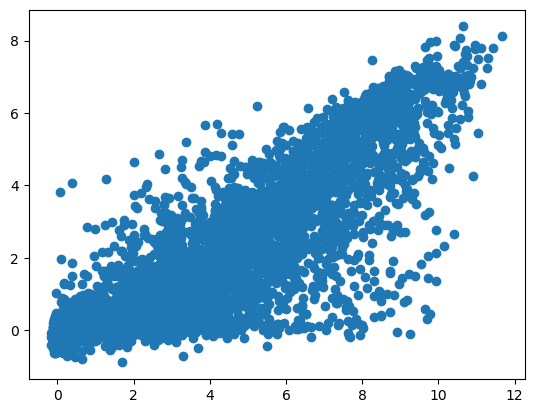

In [71]:
sandborn_data = test_data[test_data['screen'] == 'sanborn']
to_plot = [ast.literal_eval(ls)[0] for ls in sandborn_data['paddle_preds']]
plt.scatter(to_plot, sandborn_data['activity'])

In [ ]:
to_plot = [(ast.literal_eval(ls)) for ls in sandborn_data['combined_preds']]

<Axes: ylabel='activity'>

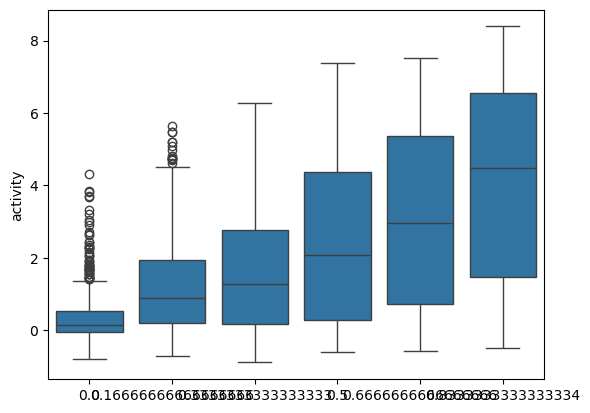

In [84]:
sandborn_data = test_data[test_data['screen'] == 'sanborn']
to_plot = [np.max(ast.literal_eval(ls)) for ls in sandborn_data['combined_preds']]

sns.boxplot(x=to_plot, y=sandborn_data['activity'])

In [ ]:
# Combining all test datapoints

In [380]:
test_data_parrot['screen'].value_counts()

screen
ravarani    27093
hummel      15864
arf          9056
sanborn      8288
delrosso      804
arnold        240
Name: count, dtype: int64

In [409]:
def active(value, threshold): 
    if not np.isnan(threshold):
        return value > threshold


In [410]:
threshold_dict = {
    'delrosso' : 3, 
    'arnold' : 2, 
    'sanborn' : 3.4, 
    'arf' : 1, 
    'hummel' : 30, 
    'ravarani' : np.nan
}

In [411]:
test_data_parrot['active'] = [active(val, threshold_dict[screen]) for val, screen in zip(test_data_parrot['activity'], test_data_parrot['screen'])]

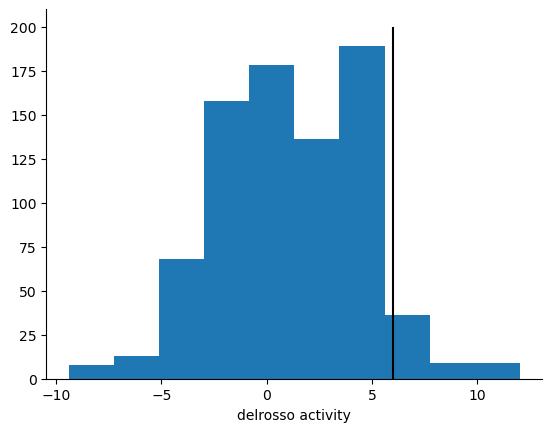

In [490]:
plt.hist(test_data_parrot[test_data_parrot['screen'] == 'delrosso']['activity'])
plt.vlines(6, 0, 200, color='black')
plt.xlabel("delrosso activity")
sns.despine()

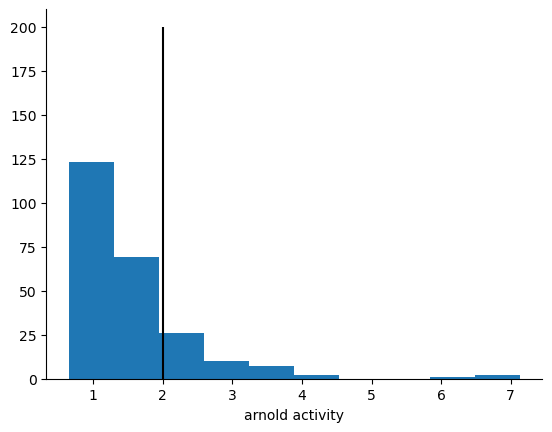

In [401]:
plt.hist(test_data_parrot[test_data_parrot['screen'] == 'arnold']['activity'])
plt.vlines(2, 0, 200, color='black')
plt.xlabel("arnold activity")
sns.despine()

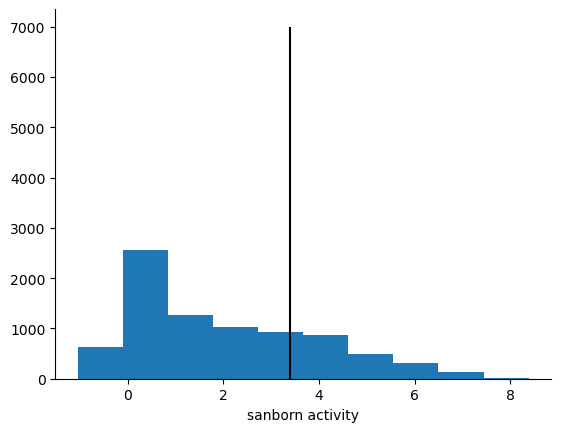

In [394]:
plt.hist(test_data_parrot[test_data_parrot['screen'] == 'sanborn']['activity'])
plt.vlines(3.4, 0, 7000, color='black')
plt.xlabel("sanborn activity")
sns.despine()

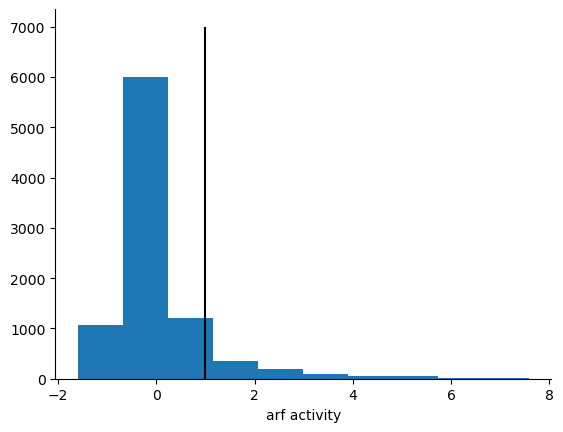

In [392]:
plt.hist(test_data_parrot[test_data_parrot['screen'] == 'arf']['activity'])
plt.vlines(1, 0, 7000, color='black')
plt.xlabel("arf activity")
sns.despine()

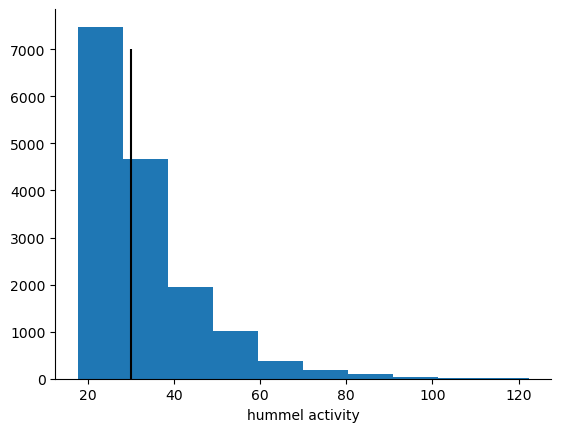

In [389]:
plt.hist(test_data_parrot[test_data_parrot['screen'] == 'hummel']['activity'])
plt.vlines(30, 0, 7000, color='black')
plt.xlabel("hummel activity")
sns.despine()

In [ ]:
plot_df = pd.DataFrame({
    'model':     ['paddle', 'tada', 'adhunter', 'adpred', 'adhunter_ensemble', 'composition', 'consensus_strict', 'consensus_medium', 'consensus_lenient'],
    'precision': [paddle_p, tada_p, adhunter_p, adpred_p, adhunter_ensemble_p, comp_p, consensus_strict_p, consensus_medium_p, consensus_lenient_p],
    'recall':    [paddle_r, tada_r, adhunter_r, adpred_r, adhunter_ensemble_r, comp_r, consensus_strict_r, consensus_medium_r, consensus_lenient_r],
    'f1':        [paddle_f1, tada_f1, adhunter_f1, adpred_f1, adhunter_ensemble_f1, comp_f1, consensus_strict_f1, consensus_medium_f1, consensus_lenient_f1],
})

# Sort by precision first, then recall
plot_df = plot_df.sort_values(['precision', 'recall'], ascending=False)

# Melt to long format
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(12, 5))
sns.barplot(data=plot_df, x='model', y='score', hue='metric', 
            palette=['steelblue', 'coral', 'mediumseagreen'],
            order=plot_df['model'].unique())  # preserve sort order

plt.xticks(rotation=45, ha='right')
plt.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
sns.despine()
plt.tight_layout()